In [6]:
import numpy as np 
import matplotlib.pylab as plt
import matplotlib.patches as patches
from scipy.stats import gaussian_kde
from matplotlib.ticker import FormatStrFormatter
import pandas as pd 
import seaborn as sns


In [ ]:
##fig2

加载参考体系...
将绘制 900 帧


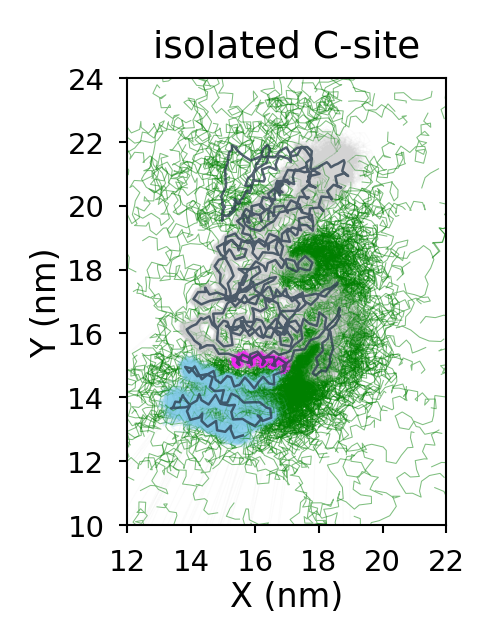

In [7]:
import mdtraj as md
import matplotlib.pyplot as plt
import numpy as np


# 1. 加载待对齐的轨迹 t
t = md.load('merged_trajectory.xtc', top='merged_topology.pdb')
top = t.topology

selection = top.select('resid 0 to 692 and name BB')
lig = top.select('resid 693 to 733 and name BB')



# 2. 加载参考体系
print("加载参考体系...")
t_ref = md.load('/home/jhsong/Menin_MLL_project/Menin-Mll/test-3-gro/Total/trajin-merge/9-withidr_M-M-L/step5_production-0_5.xtc',
                top='/home/jhsong/Menin_MLL_project/Menin-Mll/test-3-gro/Total/trajin-merge/9-withidr_M-M-L/step3_charmm2gmx.pdb')
top2 = t_ref.topology

# 3. 分别在 t 和 t_ref 上选取用于对齐的原子
t_align_atoms  = top.select('resid 0 to 449 and name BB')
ref_align_atoms = top2.select('resid 1 to 450 and name BB')


# 4. 把 t 对齐到 t_ref 的第 0 帧
t_aligned = t.superpose(t_ref, frame=0,
                        atom_indices=t_align_atoms,
                        ref_atom_indices=ref_align_atoms)

# 5. 从 t_aligned中提取坐标
xcord = t_aligned.xyz[:, selection, 0]
ycord = t_aligned.xyz[:, selection, 1]
lig_x = t_aligned.xyz[:, lig, 0]
lig_y = t_aligned.xyz[:, lig, 1]



plt.figure(figsize=(2.14,2.14), dpi=300)

regions = [
    (83, 100, 'magenta', 0.5),     
    (611, 692, 'skyblue', 0.2),    
    (0, 450, 'lightgray', 0.1)     
]

def find_helical_segments(x_coords, y_coords, max_gap=2.5):
    """基于原子间距离自动识别螺旋段"""
    segments = []
    current_segment = [0]
    
    for i in range(1, len(x_coords)):
        dist = np.sqrt((x_coords[i] - x_coords[i-1])**2 + (y_coords[i] - y_coords[i-1])**2)
        
        if dist <= max_gap:
            current_segment.append(i)
        else:
            if len(current_segment) > 2:
                segments.append(current_segment)
            current_segment = [i]
    
    if len(current_segment) > 2:
        segments.append(current_segment)
    
    return segments

# 绘制轨迹 
frames_to_plot = min(900, t_aligned.n_frames)
print(f"将绘制 {frames_to_plot} 帧")

for i in range(0, frames_to_plot, 2):
    # 绘制主链区域
    plt.plot(xcord[i, 83:100], ycord[i, 83:100], color='magenta', alpha=0.4, lw=0.25)
    plt.plot(xcord[i, 611:692], ycord[i, 611:692], color='skyblue', alpha=0.15, lw=0.25)
    plt.plot(xcord[i, 0:450], ycord[i, 0:450], color='lightgray', alpha=0.08, lw=0.25)
    
    # 绘制配体
    if lig_x.shape[1] > 0:
        segments = find_helical_segments(lig_x[i], lig_y[i])
        for segment in segments:
            if len(segment) > 1:
                plt.plot(lig_x[i, segment], lig_y[i, segment], color='green', alpha=0.5, lw=0.25)

# 绘制平均轨迹 
if xcord.shape[1] > 610:
    end_610 = min(610, xcord.shape[1])
    plt.plot(np.mean(xcord[:, 0:end_610], axis=0), 
             np.mean(ycord[:, 0:end_610], axis=0), 
             color='#2C3E50', lw=0.6, alpha=0.8)

if xcord.shape[1] > 692:
    start_611 = min(611, xcord.shape[1])
    end_692 = min(692, xcord.shape[1])
    plt.plot(np.mean(xcord[:, start_611:end_692], axis=0), 
             np.mean(ycord[:, start_611:end_692], axis=0), 
             color='#2C3E50', lw=0.6, alpha=0.8)

# 设置坐标轴范围和刻度
plt.xlim([12, 22])
plt.ylim([10, 24])

# 设置刻度和标签
plt.xticks(np.arange(12, 23, 2), fontsize=7)
plt.yticks(np.arange(10, 25, 2), fontsize=7)

# 设置坐标轴标签
plt.xlabel('X (nm)', fontsize=8, labelpad=1)
plt.ylabel('Y (nm)', fontsize=8, labelpad=1)
plt.title('isolated C-site', fontsize=9, pad=5)
# 设置边框和刻度样式
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_linewidth(0.5)



ax.tick_params(axis='both', which='major', 
               width=0.5, length=2, 
               direction='out', labelsize=7)

# 移除网格
plt.grid(False)

# 设置等比例
ax.set_aspect('equal')

# 紧凑布局
plt.tight_layout(pad=1.0)

# 保存图像
plt.savefig('trajectory_nolinker.png', dpi=300, bbox_inches='tight', 
            transparent=True)

plt.show()

In [10]:
# 分别绘制每个系统
def plot_individual_system(system_name, traj_path, top_path, ref_frame, color='#27AE60'):
    print(f"处理 {system_name}...")
    
    try:
        # 加载轨迹
        t = md.load(traj_path, top=top_path)
        top = t.topology
        
        # 选择对齐原子
        alignment_indices = top.select('resid 1 to 450 and name BB')
        if alignment_indices is None or len(alignment_indices) == 0:
            alignment_indices = top.select('protein and name BB')
        
        
        # 对齐到参考结构
        t_aligned = t.superpose(ref_frame, atom_indices=alignment_indices)
        
        # 选择原子
        selection = top.select('resid 0 to 692 and name BB')
        lig = top.select('resid 693 to 774 and name BB')
        
        
        # 提取坐标
        xcord = t_aligned.xyz[:, selection, 0]
        ycord = t_aligned.xyz[:, selection, 1]
        lig_x = t_aligned.xyz[:, lig, 0]
        lig_y = t_aligned.xyz[:, lig, 1]
        
        # 创建图形
        plt.figure(figsize=(2, 2), dpi=300)

        regions = [
                   (83, 100, 'magenta', 0.5),     
                   (611, 692, 'skyblue', 0.2),     
                   (0, 450, 'lightgray', 0.1)     
                       ]

        
        # 绘制轨迹 
        frames_to_plot = min(1000, t_aligned.n_frames)
        for i in range(0, frames_to_plot, 2):
            for start, end, region_color, alpha in regions:
                if xcord.shape[1] > end:
                    plt.plot(xcord[i, start:end], ycord[i, start:end], 
                     color=region_color, alpha=alpha, lw=0.25)
            
            # 绘制配体
            if lig_x.shape[1] > 60:
                plt.plot(lig_x[i, 41:81], lig_y[i, 41:81], 
                        color=color, alpha=0.4, lw=0.25)
        
        
        # 平均轨迹 
        if xcord.shape[1] > 610:
            plt.plot(np.mean(xcord[:,0:610], axis=0), np.mean(ycord[:,0:610], axis=0), 
                    color='#2C3E50', lw=0.6, alpha=0.8)
        
        if xcord.shape[1] > 692:
            plt.plot(np.mean(xcord[:,611:692], axis=0), np.mean(ycord[:,611:692], axis=0), 
                    color='#2C3E50', lw=0.6, alpha=0.8)
        

        # 设置坐标轴范围和刻度
        plt.xlim([12, 22])
        plt.ylim([10, 24])
        

        
        # 设置坐标轴标签
        plt.xlabel('X (nm)')
        plt.ylabel('')
        
        # 设置标题 - 小字体
        plt.title(system_name)
        
        # 设置边框和刻度样式
        ax = plt.gca()

                
        # 设置等比例
        ax.set_aspect('equal')
        
        # 紧凑布局
       # plt.tight_layout(pad=1.0)

    
        plt.savefig(f'trajectory_{system_name.replace(" ", "_")}.png', 
                dpi=300, bbox_inches='tight', 
               transparent=True)    
        
    except Exception as e:
        print(f"错误: {e}")

print("函数定义完成，可以调用 plot_individual_system() 了")

函数定义完成，可以调用 plot_individual_system() 了


In [11]:
# 加载参考结构
print("加载参考体系...")
t_ref = md.load('/home/jhsong/Menin_MLL_project/Menin-Mll/test-3-gro/Total/trajin-merge/9-withidr_M-M-L/step5_production-0_5.xtc', 
                top='/home/jhsong/Menin_MLL_project/Menin-Mll/test-3-gro/Total/trajin-merge/9-withidr_M-M-L/step3_charmm2gmx.pdb')
ref_frame = t_ref[0]


加载参考体系...


处理 S1...


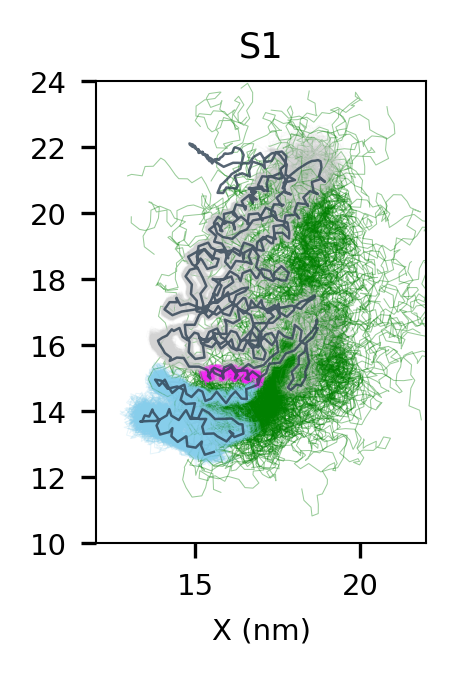

In [12]:
plot_individual_system('S1', 
                      '/home/jhsong/Menin_MLL_project/Menin-Mll/test-3-gro/Total/trajin-merge/11-noidr-M-M-L/step5_production-0.5-5.xtc',
                      '/home/jhsong/Menin_MLL_project/Menin-Mll/test-3-gro/Total/trajin-merge/11-noidr-M-M-L/step3_charmm2gmx.pdb',
                      ref_frame, 'green')

处理 S2...


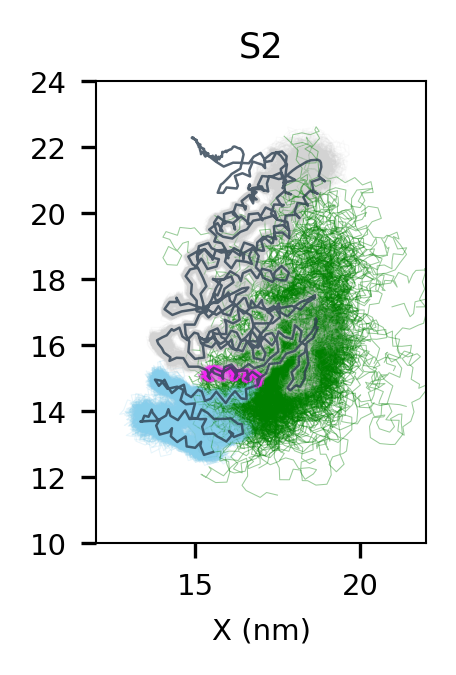

In [13]:
plot_individual_system('S2', 
                      '/home/jhsong/Menin_MLL_project/Menin-Mll/test-3-gro/Total/trajin-merge/14-noidr-mbm2-M-L/step5_production1_0.5-5.xtc',
                      '/home/jhsong/Menin_MLL_project/Menin-Mll/test-3-gro/Total/trajin-merge/14-noidr-mbm2-M-L/step3_charmm2gmx.pdb',
                      ref_frame, 'green')


In [14]:
import mdtraj as md
import matplotlib.pyplot as plt
import numpy as np



# 分别绘制每个系统
def plot_individual_system(system_name, traj_path, top_path, ref_frame, color='#27AE60'):
    print(f"处理 {system_name}...")
    
    try:
        # 加载轨迹
        t = md.load(traj_path, top=top_path)
        top = t.topology
        
        # 选择对齐原子
        alignment_indices = top.select('resid 1 to 450 and name BB')
        if alignment_indices is None or len(alignment_indices) == 0:
            alignment_indices = top.select('protein and name BB')
        
        
        # 对齐到参考结构
        t_aligned = t.superpose(ref_frame, atom_indices=alignment_indices)
        
        # 选择原子
        selection = top.select('resid 0 to 692 and name BB')
        lig = top.select('resid 693 to 841 and name BB')
        
        
        # 提取坐标
        xcord = t_aligned.xyz[:, selection, 0]
        ycord = t_aligned.xyz[:, selection, 1]
        lig_x = t_aligned.xyz[:, lig, 0]
        lig_y = t_aligned.xyz[:, lig, 1]
        
        # 创建图形 - Nature Methods紧凑尺寸
        plt.figure(figsize=(2,2), dpi=300)

        regions = [
                   (83, 100, 'magenta', 0.5),      
                   (611, 692, 'skyblue', 0.2),     
                   (0, 450, 'lightgray', 0.1)      
                       ]

        
        # 绘制轨迹 - 更细的线条
        frames_to_plot = min(1000, t_aligned.n_frames)
        for i in range(0, frames_to_plot, 2):
            for start, end, region_color, alpha in regions:
                if xcord.shape[1] > end:
                    plt.plot(xcord[i, start:end], ycord[i, start:end], 
                     color=region_color, alpha=alpha, lw=0.25)
            
            # 绘制配体
            if lig_x.shape[1] > 108:
                plt.plot(lig_x[i, 108:148], lig_y[i, 108:149], 
                        color=color, alpha=0.4, lw=0.25)
        
        # 平均轨迹
        if xcord.shape[1] > 610:
            plt.plot(np.mean(xcord[:,0:610], axis=0), np.mean(ycord[:,0:610], axis=0), 
                    color='#2C3E50', lw=0.6, alpha=0.8)
        
        if xcord.shape[1] > 692:
            plt.plot(np.mean(xcord[:,611:692], axis=0), np.mean(ycord[:,611:692], axis=0), 
                    color='#2C3E50', lw=0.6, alpha=0.8)
        

        # 设置坐标轴范围和刻度
        plt.xlim([12, 22])
        plt.ylim([10, 24])
        
        
        # 设置坐标轴标签
        plt.xlabel('X (nm)')
        plt.ylabel('')
        
        # 设置标题 
        plt.title(system_name)
        
        # 设置边框和刻度样式
        ax = plt.gca()
        
        # 设置等比例
        ax.set_aspect('equal')
        

        plt.savefig(f'trajectory_{system_name.replace(" ", "_")}.png', 
                dpi=300, bbox_inches='tight', 
               transparent=True) 
    except Exception as e:
        print(f"错误: {e}")

print("函数定义完成，可以调用 plot_individual_system() 了")

函数定义完成，可以调用 plot_individual_system() 了


处理 S3...


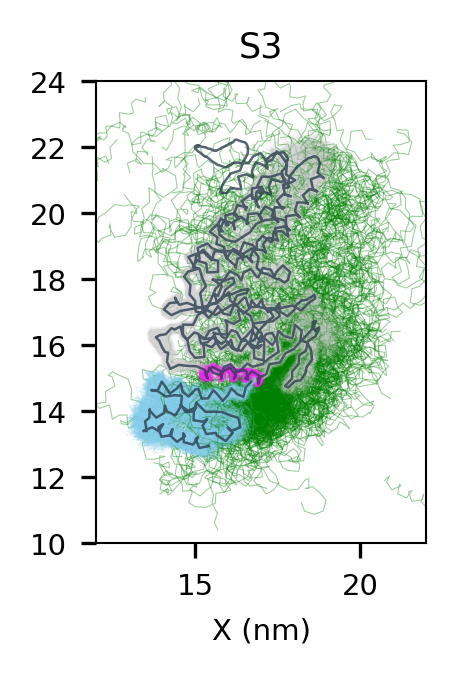

In [15]:
# 分别绘制
plot_individual_system('S3', 
                      '/home/jhsong/Menin_MLL_project/Menin-Mll/test-3-gro/Total/trajin-merge/9-withidr_M-M-L/step5_production-0_5.xtc',
                      '/home/jhsong/Menin_MLL_project/Menin-Mll/test-3-gro/Total/trajin-merge/9-withidr_M-M-L/step3_charmm2gmx.pdb',
                      ref_frame, 'green')


处理 S4...


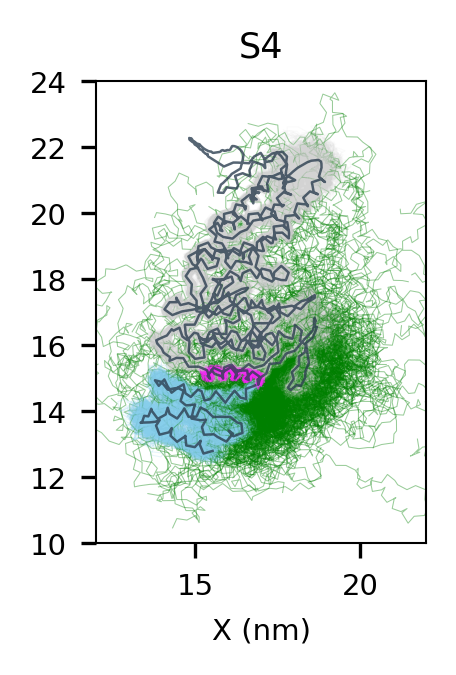

In [16]:
plot_individual_system( 'S4', 
                      '/home/jhsong/Menin_MLL_project/Menin-Mll/test-3-gro/Total/trajin-merge/17-withidr-mbm2-M-L/step5_production_0_5.xtc',
                      '/home/jhsong/Menin_MLL_project/Menin-Mll/test-3-gro/Total/trajin-merge/17-withidr-mbm2-M-L/step3_charmm2gmx.pdb',
                      ref_frame, 'green')

In [ ]:
##fig3

构象分布在粉色区域内的概率比例: 0.0416 (4.16%)
粉色区域绝对概率质量: 0.041488
整个构象空间总概率质量: 0.996517
归一化验证: 0.041633


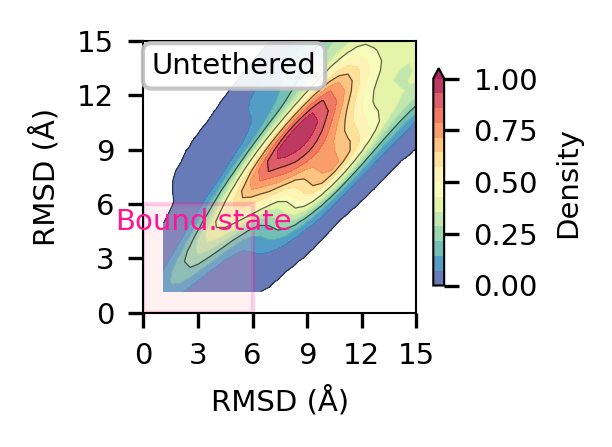

In [18]:
import matplotlib.patches as patches
from matplotlib.patches import Rectangle
rmsd1 = np.loadtxt('/home/jhsong/Menin_MLL_project/Menin-Mll/test-3-gro/Total/trajin-merge/total-MLL-function/rmsd-IDR1-5000-led3-mll3.dat', comments="#")
rmsd2 = np.loadtxt('/home/jhsong/Menin_MLL_project/Menin-Mll/test-3-gro/Total/trajin-merge/total-MLL-function/rmsd-IDR1-5000-men-mll.dat', comments="#")


x = np.array(rmsd1[:, 1])
y = np.array(rmsd2[:, 1])
min_length = min(len(x), len(y))
x = x[:min_length]
y = y[:min_length]

xy = np.vstack([x, y])
z = gaussian_kde(xy)(xy)

z_normalized = (z - z.min()) / (z.max() - z.min())

cmap = 'Spectral_r'

# 创建画布
fig, ax = plt.subplots(figsize=(2,1.5), dpi=300)

xi = np.linspace(x.min(), x.max(), 150)
yi = np.linspace(y.min(), y.max(), 150)
xi, yi = np.meshgrid(xi, yi)
xy_grid = np.vstack([xi.flatten(), yi.flatten()])
zi = gaussian_kde(xy)(xy_grid)
zi = zi.reshape(xi.shape)
zi_normalized = (zi - zi.min()) / (zi.max() - zi.min())

# 设置等高线密度范围
density_min = 0.001
density_max = zi_normalized.max()
contour_levels = np.linspace(density_min, density_max, 15)

# 绘制等高线填充
contourf = ax.contourf(xi, yi, zi_normalized, 
                       levels=contour_levels, 
                       cmap=cmap, 
                       alpha=0.85,
                       vmin=density_min,
                       vmax=density_max,
                       extend='max')

# 绘制等高线
contour_lines = ax.contour(xi, yi, zi_normalized, 
                          levels=contour_levels[::3],
                          colors='black', 
                          linewidths=0.3, 
                          alpha=0.6,
                          linestyles='-')


# 设置坐标轴范围
ax.set_xlim([0, 15])
ax.set_ylim([0, 15])

# 设置刻度和标签
ax.set_xticks(np.arange(0, 16, 3))
ax.set_yticks(np.arange(0, 16, 3))


# 设置轴标签
ax.set_xlabel('RMSD (Å)')
ax.set_ylabel('RMSD (Å)')
cbar = plt.colorbar(contourf, 
                   shrink=0.8, 
                   aspect=20, 
                   pad=0.05,
                   orientation='vertical')
cbar.set_label('Density')


# 设置颜色条刻度
cbar_ticks = np.linspace(density_min, density_max, 5)
cbar.set_ticks(cbar_ticks)
cbar.set_ticklabels([f'{tick:.2f}' for tick in cbar_ticks])


# 添加标签 
ax.annotate('Untethered', 
            xy=(0.03, 0.96), 
            xycoords='axes fraction',
            color='black',
            bbox=dict(boxstyle="round,pad=0.3", 
                     facecolor='white', 
                     alpha=0.9, 
                     edgecolor='silver', 
                     linewidth=1),
            ha='left', 
            va='top',
            zorder=10)



# 添加长方形区域
rect = Rectangle((0, 0), 6, 6, 
                 linewidth=1, 
                 edgecolor='#FF1493', # 深粉色边框
                 facecolor='#FFB6C1',# 浅粉色填充 
                 alpha=0.2, 
                 label='Act.state')
ax.add_patch(rect)

ax.text(3.3, 5, 'Bound.state', 
        fontsize=7, 
        color='#FF1493',
        ha='center',
        va='center',
        zorder=10)

# 优化布局
plt.savefig('linker_no.png', dpi=300, bbox_inches='tight', 
            transparent=True)
plt.tight_layout()


# 定义粉色区域范围 

pink_region_x_range = [0, 6]  # X轴范围
pink_region_y_range = [0, 6]    # Y轴范围

# 更精确的体积计算方法
def calculate_region_volume_ratio(x_data, y_data, x_range, y_range, grid_resolution=100):
    """计算指定区域在整个构象空间的体积比例"""
    x_grid = np.linspace(x_data.min(), x_data.max(), grid_resolution)
    y_grid = np.linspace(y_data.min(), y_data.max(), grid_resolution)
    X, Y = np.meshgrid(x_grid, y_grid)
    
    # 计算整个空间的密度
    xy_all = np.vstack([x_data, y_data])
    kde_all = gaussian_kde(xy_all)
    positions = np.vstack([X.ravel(), Y.ravel()])
    Z = kde_all(positions).reshape(X.shape)
    
    # 提取目标区域
    region_mask = (X >= x_range[0]) & (X <= x_range[1]) & \
                  (Y >= y_range[0]) & (Y <= y_range[1])
    
    # 计算体积
    dx = x_grid[1] - x_grid[0]
    dy = y_grid[1] - y_grid[0]
    
    # 计算粉色区域体积和总体积
    region_volume = np.sum(Z[region_mask]) * dx * dy
    total_volume = np.sum(Z) * dx * dy
    
    # 计算比例
    volume_ratio = region_volume / total_volume
    
    return volume_ratio, region_volume, total_volume, Z, X, Y, region_mask

# 使用修正的函数计算
volume_ratio, region_vol, total_vol, Z_full, X_full, Y_full, mask = calculate_region_volume_ratio(
    x, y, pink_region_x_range, pink_region_y_range)

print(f"构象分布在粉色区域内的概率比例: {volume_ratio:.4f} ({volume_ratio*100:.2f}%)")
print(f"粉色区域绝对概率质量: {region_vol:.6f}")
print(f"整个构象空间总概率质量: {total_vol:.6f}")
print(f"归一化验证: {region_vol/total_vol:.6f}")




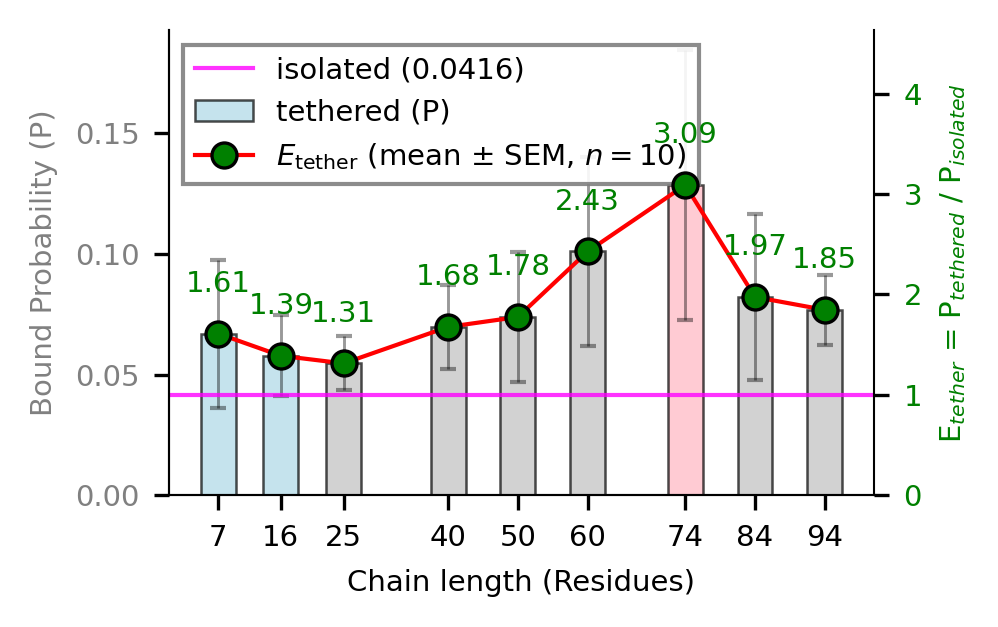

In [8]:
import matplotlib.pyplot as plt
import numpy as np


Ceff_replicates = np.array([
    [0.0817, 1.0481, 0.4303, 3.1538, 0.5409, 0.5962, 1.6731, 0.3726, 7.7284, 0.4760],  # N=7
    [2.5288, 1.6274, 2.0865, 0.6202, 0.2043, 0.0889, 3.0673, 0.0192, 0.3870, 3.2596],  # N=16
    [0.4014, 1.7139, 0.4639, 0.3221, 2.1851, 2.0745, 1.7380, 1.2260, 2.5505, 0.4543],  # N=25
    [0.4543, 3.0697, 0.4784, 2.1106, 0.6202, 1.7067, 0.0000, 1.5264, 3.9856, 2.8173],  # N=40
    [0.1538, 0.1634, 1.5577, 0.0000, 2.2740, 2.9111, 0.5962, 2.4207, 0.8558, 6.8197],  # N=50
    [0.2981, 0.0072, 0.0865, 5.5817, 2.1755, 2.0938, 0.0553, 7.2139, 0.0000, 6.7668],  # N=60
    [6.1178, 0.9856, 13.8365, 0.0000, 4.2981, 2.4303, 1.6250, 1.1370, 0.2284, 0.2404], # N=74
    [1.3462, 1.3774, 0.4014, 0.4543, 1.9639, 6.1298, 7.4135, 0.3726, 0.1490, 0.1346],  # N=84
    [2.3317, 1.8486, 1.6298, 0.5072, 1.6683, 4.2716, 2.5769, 2.0553, 1.1322, 0.4423]   # N=94
])

# 链长标签
seq_names = ["7","16","25", "40", "50", "60", "74", "84", "94"]
linker_values = [7,16,25, 40, 50, 60, 74, 84, 94]

# Untethered 结合概率
untethered_bound = 0.0416


n_replicates = Ceff_replicates.shape[1]   # 10

ceff_mean = np.mean(Ceff_replicates, axis=1)
ceff_std = np.std(Ceff_replicates, axis=1, ddof=1)   # 样本标准差
ceff_sem = ceff_std / np.sqrt(n_replicates)

# 结合概率 = Ceff × untethered_bound
tethered_mean = ceff_mean * untethered_bound
tethered_sem = ceff_sem * untethered_bound

ceff = ceff_mean


fig, ax1 = plt.subplots(figsize=(3.4, 2.1), dpi=300)

# 颜色定义
color_tethered = '#2E86AB'   # 蓝色（柱状）
color_ceff = '#E63946'        # 红色（折线）

# 柱状图颜色（按条件特殊标记）
bar_colors = []
for i, length in enumerate(linker_values):
    if length == 7 or length == 16:
        bar_colors.append('lightblue')
    elif length == 74:
        bar_colors.append('lightpink')
    else:
        bar_colors.append('silver')

# 绘制左侧柱状图（结合概率）
bars = ax1.bar(linker_values, tethered_mean, 
               width=5, alpha=0.7, color=bar_colors,
               edgecolor='black', linewidth=0.6,
               label='tethered (P)')

# 添加真实误差棒（标准误差）
ax1.errorbar(linker_values, tethered_mean, yerr=tethered_sem,
             fmt='none', ecolor='black', capsize=2, capthick=1, alpha=0.4, linewidth=0.7)

# Untethered 参考线
ax1.axhline(y=untethered_bound, color='magenta', linestyle='-',
            linewidth=1, alpha=0.8,
            label=f'isolated ({untethered_bound:.4f})')

# 左侧 y 轴设置
ax1.set_xlabel('Chain length (Residues)', )
ax1.set_ylabel('Bound Probability (P)',  color='gray')
ax1.tick_params(axis='y', labelcolor='gray')
ax1.set_xticks(linker_values)
ax1.set_xticklabels(seq_names, rotation=0, ha='center')
ax1.set_ylim(0, max(tethered_mean) * 1.5)

# 右侧 y 轴
ax2 = ax1.twinx()
line = ax2.plot(linker_values, ceff, 'o-', color='red',
                linewidth=1, markersize=6,
                markerfacecolor='green',
                markeredgecolor='black', markeredgewidth=0.8,
                label=f'$E_{{\\mathrm{{tether}}}}$ (mean $\\pm$ SEM, $n=10$)')

# 添加 Ceff 数值标签
for i, (x_val, y_val) in enumerate(zip(linker_values, ceff)):
    ax2.annotate(f'{y_val:.2f}',
                 xy=(x_val, y_val),
                 xytext=(0, 10),
                 textcoords='offset points',
                 ha='center',
                 fontsize=7,
                 color='green')

# 右侧 y 轴设置
ax2.set_ylabel('E$_{tether}$ = P$_{tethered}$ / P$_{isolated}$',
                color='green')
ax2.tick_params(axis='y', labelcolor='green')
ax2.set_ylim(0, max(ceff) * 1.5)

# 美化细节
ax1.grid(False)          # 关闭网格
ax2.grid(False)
ax1.tick_params(axis='both')
ax2.tick_params(axis='y')

# 边框处理
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax2.spines['top'].set_visible(False)


# 图例合并
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
legend = ax1.legend(lines1 + lines2, labels1 + labels2,
                    loc='upper left', frameon=True,
                    fancybox=False, edgecolor='grey',
                    framealpha=0.9)

plt.tight_layout()
plt.savefig('ceff_enhancement_analysis.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [ ]:
##fig4

Ternary ν = 0.4914 ± 0.0045
Monomer ν = 0.4959 ± 0.0063


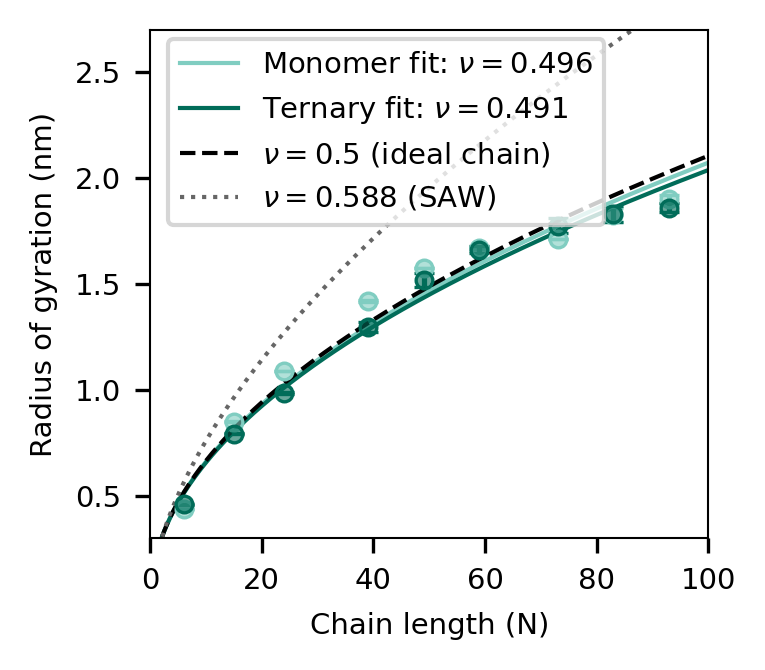

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy import stats


# 1. 输入原始数据 (单位: Å)

trenary_data_angstrom = np.array([
    [4.54,7.91,9.86, 13.78, 15.02, 16.62, 16.66, 18.58, 19.30],
    [4.54,7.84,9.99, 12.85, 15.82, 16.09, 17.17, 19.61, 18.97],
    [4.56,7.88,9.77, 12.84, 15.00, 16.89, 16.21, 19.57, 18.01],
    [4.59,8.02,9.91, 13.05, 17.61, 16.39, 20.11, 17.68, 19.16],
    [4.61,8.01,9.93, 12.14, 15.27, 15.92, 18.45, 18.81, 18.89],
    [4.58,7.86,9.88, 14.17, 14.82, 16.47, 18.53, 17.10, 17.69],
    [4.66,8,9.63, 13.57, 14.83, 17.95, 17.40, 16.74, 17.28],
    [4.58,7.81,9.67, 12.23, 14.62, 16.49, 18.05, 16.89, 18.69],
    [4.62,8.16,9.69, 12.04, 15.08, 16.51, 17.85, 18.13, 19.06],
    [4.65,7.91,10.03, 13.15, 13.87, 16.88, 17.19, 20.12, 19.02]
])

monomer_data_angstrom = np.array([
    [4.36,8.53,10.88, 14.09, 15.78, 16.62, 17.12, 17.69, 19.01],
    [4.37,8.5,10.87, 14.27, 15.77, 16.78, 17.16, 18.20, 19.37],
    [4.36,8.46,10.92, 14.21, 15.77, 16.69, 17.13, 18.85, 18.63]
])

N = np.array([6,15,24, 39, 49, 59, 73, 83, 93])

trenary_data_nm = trenary_data_angstrom / 10.0
monomer_data_nm  = monomer_data_angstrom / 10.0

# 2. 统计量
trenary_mean = np.mean(trenary_data_nm, axis=0)
trenary_std  = np.std (trenary_data_nm, axis=0, ddof=1)
trenary_sem  = trenary_std / np.sqrt(10)

monomer_mean = np.mean(monomer_data_nm, axis=0)
monomer_std  = np.std (monomer_data_nm, axis=0, ddof=1)
monomer_sem  = monomer_std / np.sqrt(3)

# 3. 常数
b  = 0.38
lp = 0.35

def polymer_Rg(N, nu):
    prefactor = np.sqrt((2 * lp * b) / ((2 * nu + 1) * (2 * nu + 2)))
    return prefactor * (N ** nu)

#拟合
popt1, pcov1 = curve_fit(polymer_Rg, N, trenary_mean, p0=[0.5])
nu_fit1 = popt1[0]
nu_std1 = np.sqrt(np.diag(pcov1))[0]

popt2, pcov2 = curve_fit(polymer_Rg, N, monomer_mean, p0=[0.5])
nu_fit2 = popt2[0]
nu_std2 = np.sqrt(np.diag(pcov2))[0]

print(f"Ternary ν = {nu_fit1:.4f} ± {nu_std1:.4f}")
print(f"Monomer ν = {nu_fit2:.4f} ± {nu_std2:.4f}")


nu_theta, nu_saw = 0.5, 0.588

#  绘图
N_plot = np.linspace(0, 100, 200)

Rg_fit1  = polymer_Rg(N_plot, nu_fit1)
Rg_fit2  = polymer_Rg(N_plot, nu_fit2)
Rg_theta = polymer_Rg(N_plot, nu_theta)
Rg_saw   = polymer_Rg(N_plot, nu_saw)

plt.figure(figsize=(2.4, 2.2), dpi=300)

# Monomer 
plt.errorbar(N, monomer_mean, yerr=monomer_sem,
             fmt='o', color='#80cdc1',
             markerfacecolor=(0.502, 0.804, 0.757, 0.6),
             markeredgecolor='#80cdc1', markeredgewidth=0.8,
             capsize=2.5, elinewidth=1.25, markersize=4)

# Trenary 
plt.errorbar(N, trenary_mean, yerr=trenary_sem,
             fmt='o', color='#016c59',
             markerfacecolor=(0.006, 0.424, 0.349, 0.6),
             markeredgecolor='#016c59', markeredgewidth=0.8,
             capsize=2.5, elinewidth=1.25, markersize=4)


plt.plot(N_plot, Rg_fit2, color='#80cdc1', linestyle='-', linewidth=1,
         label=rf'Monomer fit: $\mathit{{\nu}}={nu_fit2:.3f}$')
plt.plot(N_plot, Rg_fit1, color='#016c59', linestyle='-', linewidth=1,
         label=rf'Ternary fit: $\mathit{{\nu}}={nu_fit1:.3f}$')

plt.plot(N_plot, Rg_theta, color='black', linestyle='--', linewidth=1,
         label=r'$\mathit{\nu}=0.5$ (ideal chain)')
plt.plot(N_plot, Rg_saw, color='#666666', linestyle=':', linewidth=1,
         label=r'$\mathit{\nu}=0.588$ (SAW)')

plt.xlabel('Chain length (N)')
plt.ylabel('Radius of gyration (nm)')

plt.legend(loc='upper right', bbox_to_anchor=(0.84, 1.01))

plt.xlim(0, 100)
plt.ylim(0.3, 2.7)

plt.savefig('nu_rog_nat_with_errorbars.png', dpi=300, bbox_inches='tight', 
            transparent=True)
plt.show()

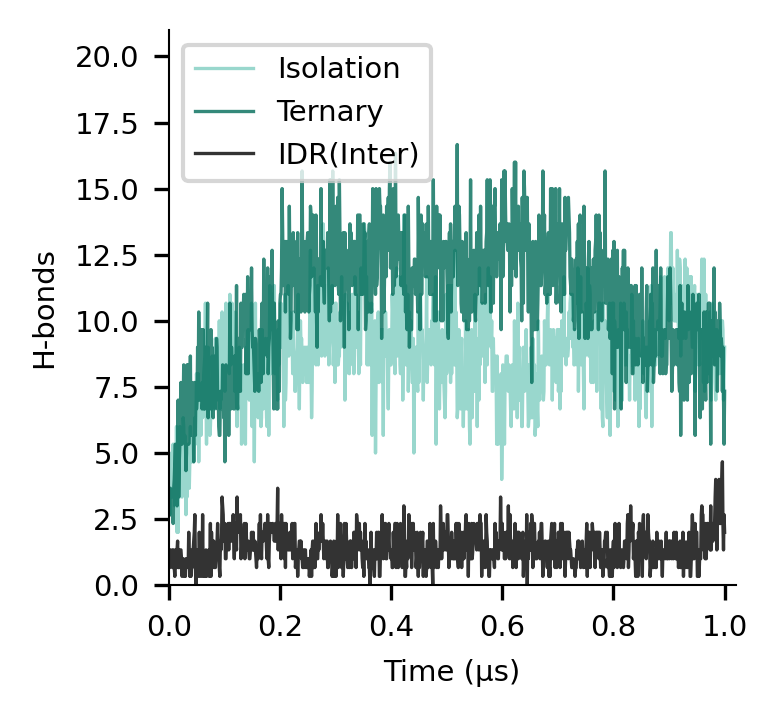

In [22]:
import numpy as np
import matplotlib.pyplot as plt


# 加载数据
hbond1 = np.loadtxt("/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/7-MLL-alone/Analysis/A-MLL-hbond.dat")
hbond2 = np.loadtxt("/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/7-MLL-alone2/analysis/A-MLL-hbond.dat")
hbond3 = np.loadtxt("/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/7-MLL-alone4/Analysis/A-MLL-hbond.dat")

hbond4 = np.loadtxt("/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/Trajin/6-M-M-L-withidr/MLL-hbond1-inter.dat")
hbond5 = np.loadtxt("/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/Trajin/6-M-M-L-withidr/MLL-hbond2-inter.dat")
hbond6 = np.loadtxt("/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/Trajin/6-M-M-L-withidr/MLL-hbond3-inter.dat")

hbond7 = np.loadtxt("/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/Trajin/6-M-M-L-withidr/hbond1.dat")
hbond8 = np.loadtxt("/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/Trajin/6-M-M-L-withidr/hbond2.dat")
hbond9 = np.loadtxt("/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/Trajin/6-M-M-L-withidr/hbond3.dat")

hbond_complex = (hbond4[:, 1] + hbond5[:, 1] + hbond6[:, 1]) / 3

hbond_alone = (hbond1[:, 1]+hbond2[:, 1]+hbond3[:, 1])/3

hbond_inter = (hbond7[:, 1] + hbond8[:, 1] + hbond9[:, 1]) / 3


plt.figure(figsize=(2.6, 2.4), dpi=300)

# 使用折线图
ax = plt.gca()

ax.plot(hbond1[:, 0] * 0.001, hbond_alone, 
        color='#80cdc1', linewidth=0.8, alpha=0.8, label='Isolation')
ax.plot(hbond4[:, 0] * 0.001, hbond_complex, 
        color='#016c59', linewidth=0.8, alpha=0.8, label='Ternary')
ax.plot(hbond7[:, 0] * 0.001,  hbond_inter, 
        color='black', linewidth=0.8, alpha=0.8, label='IDR(Inter)')
# 坐标轴设置
ax.set_xlabel('Time (μs)')
ax.set_ylabel('H-bonds')
ax.set_ylim(0, 21)
ax.set_xlim(0,1.02)

ax.tick_params(axis='x', labelbottom=True, bottom=True)
ax.tick_params(axis='y', labelleft=True, left=True)

ax.legend(loc='upper left')


# 移除上边框和右边框
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()

plt.savefig('H-bonds-vs.png', dpi=300, bbox_inches='tight', 
            transparent=True)
plt.show()

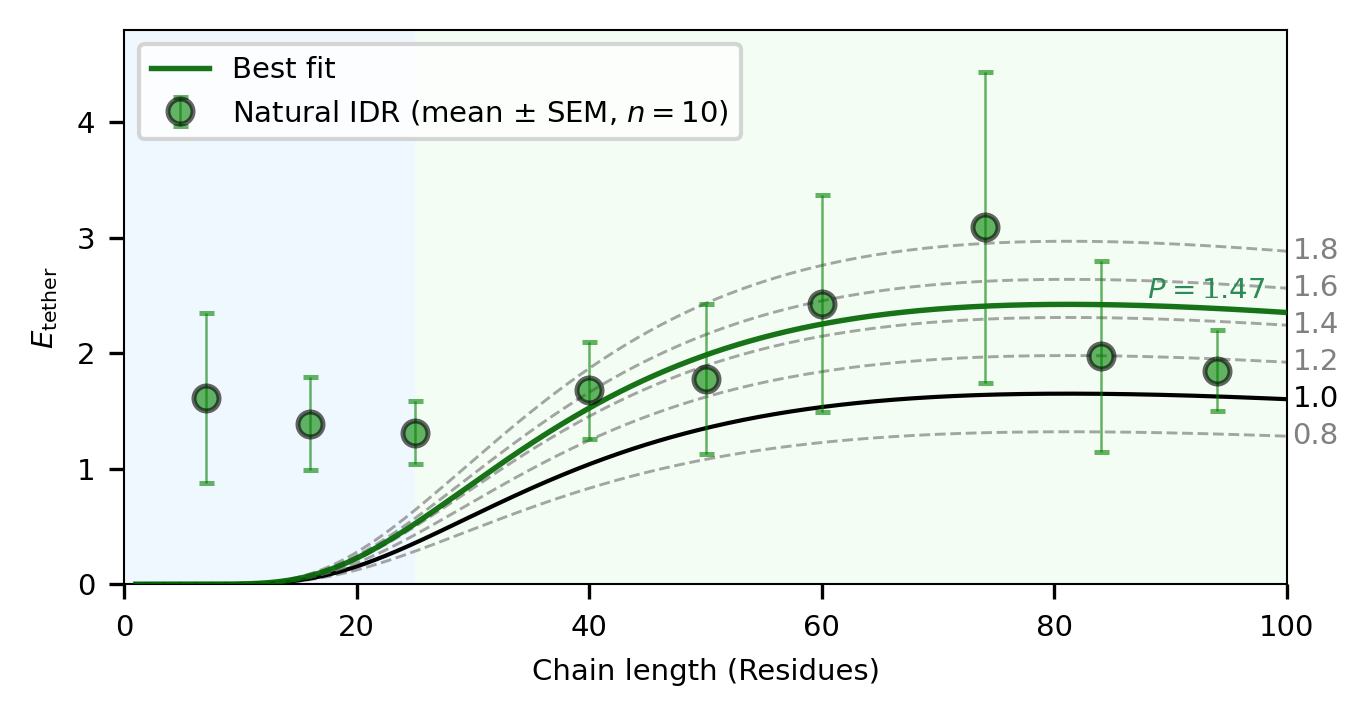

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from sklearn.metrics import mean_squared_error



# 1. E_tether = P_tethered / P_untethered  的 10 次重复
E_tether_replicates = np.array([
    [0.0817, 1.0481, 0.4303, 3.1538, 0.5409, 0.5962, 1.6731, 0.3726, 7.7284, 0.4760],  # N=7
    [2.5288, 1.6274, 2.0865, 0.6202, 0.2043, 0.0889, 3.0673, 0.0192, 0.3870, 3.2596],  # N=16
    [0.4014, 1.7139, 0.4639, 0.3221, 2.1851, 2.0745, 1.7380, 1.2260, 2.5505, 0.4543],  # N=25
    [0.4543, 3.0697, 0.4784, 2.1106, 0.6202, 1.7067, 0,      1.5264, 3.9856, 2.8173],  # N=40
    [0.1538, 0.1634, 1.5577, 0,      2.2740, 2.9111, 0.5962, 2.4207, 0.8558, 6.8197],  # N=50
    [0.2981, 0.0072, 0.0865, 5.5817, 2.1755, 2.0938, 0.0553, 7.2139, 0,      6.7668],  # N=60
    [6.1178, 0.9856, 13.8365,0,      4.2981, 2.4303, 1.625,  1.1370, 0.2284, 0.2404],  # N=74
    [1.3462, 1.3774, 0.4014, 0.4543, 1.9639, 6.1298, 7.4135, 0.3726, 0.1490, 0.1346],  # N=84
    [2.3317, 1.8486, 1.6298, 0.5072, 1.6683, 4.2716, 2.5769, 2.0553, 1.1322, 0.4423],  # N=94
])
N_exp = np.array([7, 16, 25, 40, 50, 60, 74, 84, 94], dtype=float)
P_untethered = 0.0416

E_mean = np.mean(E_tether_replicates, axis=1)
E_std  = np.std (E_tether_replicates, axis=1, ddof=1)
E_sem  = E_std / np.sqrt(E_tether_replicates.shape[1])



# 2. 物理参数
nu = 0.491   # Flory 指数（Natural MLL，来自完整三元复合物）
d  = 4.2     # nm
c  = 0.485   # nm

# ---- 浓度尺度 A₀--
A0_mM = 1660.0 * (3.0 / (2.0 * np.pi))**1.5 * c**(-3.0)

# 3.  f(N)
def f_N(N):
    """
    f(N) = N^{-3ν} · exp[ -(3/2)(d/c)^2 · N^{-2ν} ]
    """
    N = np.asarray(N, dtype=float)
    return N**(-3.0 * nu) * np.exp(-1.5 * (d / c)**2 * N**(-2.0 * nu))

# 4. 拟合模型：E_tether^model(N) = P · A₀ · f(N)
def model_P(N, P):
    return P * A0_mM * f_N(N)

# 5. 拟合 P
mask_fit = N_exp > 7
fit_label = "N > 7"

N_fit = N_exp[mask_fit]
E_fit = E_mean[mask_fit]

B_analytic = np.sum(E_fit * f_N(N_fit)) / np.sum(f_N(N_fit)**2)
P_analytic = B_analytic / A0_mM

popt, pcov = curve_fit(model_P, N_fit, E_fit, p0=[P_analytic])
P_fit = popt[0]
P_std = np.sqrt(np.diag(pcov))[0]

popt_all, pcov_all = curve_fit(model_P, N_exp, E_mean, p0=[P_analytic])
P_all     = popt_all[0]
P_all_std = np.sqrt(np.diag(pcov_all))[0]

rmse_fit = np.sqrt(mean_squared_error(E_fit, model_P(N_fit, P_fit)))
rmse_all = np.sqrt(mean_squared_error(E_mean, model_P(N_exp, P_all)))


# 6. 绘图
N_grid = np.linspace(1, 200, 1200)

P_values = [0.8, 1.0, 1.2, 1.4, 1.6, 1.8]

fig, ax = plt.subplots(figsize=(5, 2.4), dpi=300)
plt.xlim(0, 100)
plt.ylim(0, 4.80)

# 背景色块
ax.axvspan(0,  25, facecolor='#D0E8FF',    alpha=0.30, zorder=0)
ax.axvspan(25, 100, facecolor='lightgreen', alpha=0.10, zorder=0)

# ---- 绘制不同 P 值的理论曲线 ----
for P in P_values:
    y_grid = model_P(N_grid, P)

    if P == 1.0:
        color, ls, lw, alpha = 'black', '-',  1.0, 1.00
    else:
        color, ls, lw, alpha = 'gray',  '--', 0.7, 0.70

    plt.plot(N_grid, y_grid, lw=lw, color=color, linestyle=ls,
             alpha=alpha, zorder=2)

    y_lab = model_P(100, P)
    lab_color = 'black' if P == 1.0 else color
    plt.text(100.5, y_lab, f'{P:.1f}', fontsize=7, color=lab_color,
             va='center', ha='left',  zorder=10)

plt.errorbar(N_exp, E_mean, yerr=E_sem,
             fmt='o', color='green', ecolor='green',
             elinewidth=0.6, capsize=1.8, alpha=0.6,
             markersize=6, markeredgecolor='black', markeredgewidth=1.2,
             label=r'Natural IDR (mean $\pm$ SEM, $n=10$)', zorder=10)

plt.plot(N_grid, model_P(N_grid, P_fit),
         lw=1.3, color='darkgreen', linestyle='-', alpha=0.9,
         label=r'Best fit', zorder=8)   


x_text = 88                            
y_text = 2.45
ax.text(
    x_text, y_text,
    rf'$P_{{\mathrm{{}}}} = {P_fit:.2f}$',
    fontsize=7,
    color='seagreen',
    ha='left', va='bottom',
    weight='bold',
    zorder=15,
)



plt.xlabel('Chain length (Residues)')
plt.ylabel(r'$\mathit{E}_{\mathrm{tether}}$')


plt.legend(loc='upper left')

plt.savefig('P_value_fit.png', dpi=300,
            bbox_inches='tight', transparent=True)
plt.show()



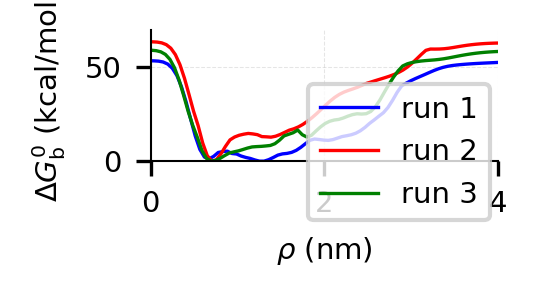

In [23]:
import numpy as np
import matplotlib.pyplot as plt

data1 = np.loadtxt('/home/jhsong/Menin_MLL_project/Menin-Mll/metad-test/MLL-7-3/GRO-pre/traj6/fes.dat')
data2 = np.loadtxt('/home/jhsong/Menin_MLL_project/Menin-Mll/metad-test/MLL-7-3/GRO-pre/traj7/fes.dat')
data3 = np.loadtxt('/home/jhsong/Menin_MLL_project/Menin-Mll/metad-test/MLL-7-3/GRO-pre/traj8/fes.dat')

# 绘图
plt.figure(figsize=(1.8, 1), dpi=300)
colors = ['blue', 'red','green']
time_labels = ['run 1', 'run 2','run 3']

rho1 = data1[:, 0]
free1 = data1[:, 3] * 0.2389
unique_rho1 = np.unique(rho1)
min_free1 = np.array([np.min(free1[rho1 == r]) for r in unique_rho1])
min_free1 = min_free1 - np.min(min_free1)

rho2 = data2[:, 0]
free2 = data2[:, 3] * 0.2389
unique_rho2 = np.unique(rho2)
min_free2 = np.array([np.min(free2[rho2 == r]) for r in unique_rho2])
min_free2 = min_free2 - np.min(min_free2)

rho3 = data3[:, 0]
free3 = data3[:, 3] * 0.2389
unique_rho3 = np.unique(rho3)
min_free3 = np.array([np.min(free3[rho3 == r]) for r in unique_rho3])
min_free3 = min_free3 - np.min(min_free3)


plt.plot(unique_rho1, min_free1, '-', color='blue', linewidth=0.8, label='run 1')
plt.plot(unique_rho2, min_free2, '-', color='red', linewidth=0.8, label='run 2')
plt.plot(unique_rho3, min_free3, '-', color='green', linewidth=0.8, label='run 3')

# 设置坐标轴范围
plt.xlim(0, 4)
plt.ylim(0, 70)

# 标签和标题
plt.xlabel(r'$\rho$ (nm)')
plt.ylabel(r'$\Delta G^0_{\mathrm{b}}$ (kcal/mol)')
# 图例
plt.legend(loc='upper right', bbox_to_anchor=(1.02, 0.7))

# 网格
plt.grid(True, alpha=0.2, linewidth=0.25, linestyle='--', color='gray')

# 设置边框和刻度样式
ax = plt.gca()

# 移除上边框和右边框
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.savefig('energy-run123.png', dpi=300, bbox_inches='tight', 
            transparent=True)
plt.tight_layout()

plt.show()

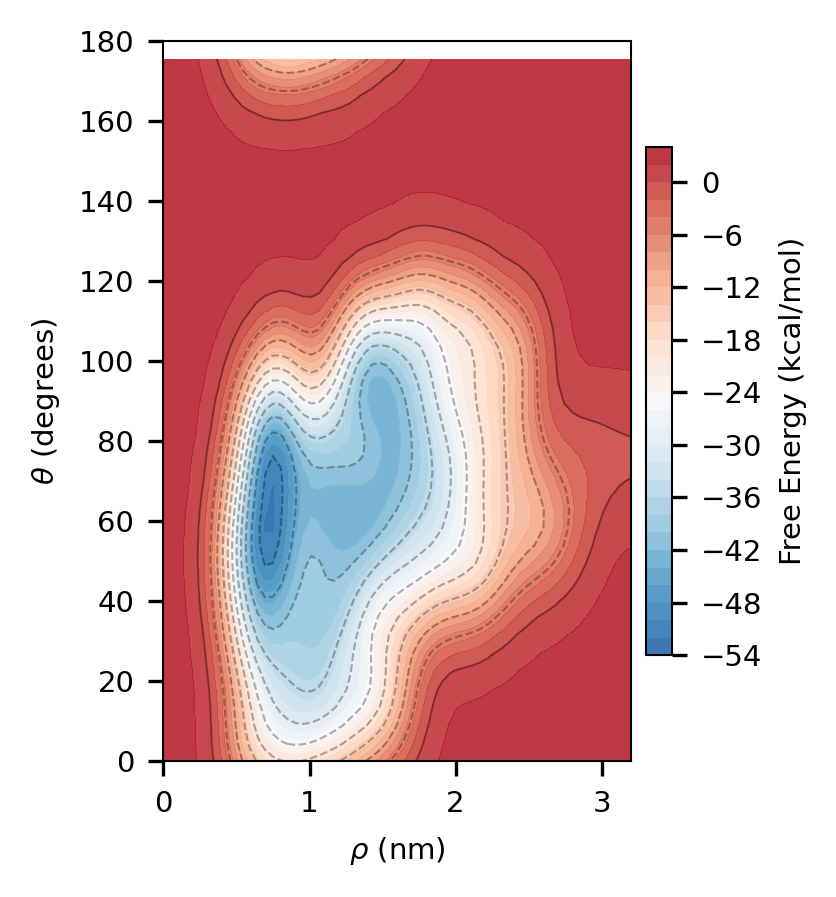

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import griddata
from matplotlib.colors import LinearSegmentedColormap

# ==================== 修正参数 ====================
R = 1.987e-3       # 气体常数 kcal/(mol·K)
T = 300.0          # 模拟温度 K
V_prot = 41850.0   # 蛋白体积 Å³
rho_s_A = 32.0     # 约束球半径 Å
rho_s_nm = 32.0 / 10.0

V_sphere = (4.0 / 3.0) * np.pi * (rho_s_A ** 3)
V_available = V_sphere - V_prot
V0 = 1660.0        # 标准浓度体积 Å³
correction = -R * T * np.log(V0 / V_available)

# ==================== 读取 FES 数据 ====================
fes_data = np.loadtxt(
    '/home/jhsong/Menin_MLL_project/Menin-Mll/metad-test/MLL-7-3/GRO-pre/traj8/fes.dat',
    comments='#'
)
rho_fes = fes_data[:, 0]        # nm
theta_fes = fes_data[:, 1]      # rad
phi_fes = fes_data[:, 2]        # rad
free_energy_raw = fes_data[:, 3] * 0.2389  # kJ/mol → kcal/mol

free_energy = free_energy_raw + correction

theta_deg = np.degrees(theta_fes)
phi_deg = np.degrees(phi_fes)

target_phi = -80
phi_tolerance = 15.0

phi_mask = np.abs(phi_deg - target_phi) < phi_tolerance

rho_sub = rho_fes[phi_mask]
theta_sub = theta_fes[phi_mask]
phi_sub = phi_fes[phi_mask]
free_energy_sub = free_energy[phi_mask]

rho_unique = np.unique(rho_sub)
theta_unique = np.unique(theta_sub)

rho_grid, theta_grid = np.meshgrid(rho_unique, theta_unique)
free_energy_grid = np.full_like(rho_grid, np.nan)

for i, rho_val in enumerate(rho_unique):
    for j, theta_val in enumerate(theta_unique):
        mask = (
            (np.abs(rho_sub - rho_val) < 1e-6)
            & (np.abs(theta_sub - theta_val) < 1e-6)
        )
        if np.any(mask):
            free_energy_grid[j, i] = free_energy_sub[mask][0]

if np.any(np.isnan(free_energy_grid)):
    points = np.column_stack([rho_sub, theta_sub])
    free_energy_grid = griddata(
        points,
        free_energy_sub,
        (rho_grid, theta_grid),
        method='cubic'
    )

# ==================== 绘制自由能面 ====================
fig, ax = plt.subplots(figsize=(2.8, 3), dpi=300)

colors = [
    '#2166AC',  # 深蓝（最低能量）
    '#4393C3',  # 中蓝
    '#92C5DE',  # 浅蓝
    '#D1E5F0',  # 非常浅的蓝
    '#F7F7F7',  # 近乎白色
    '#FDDBC7',  # 非常浅的橙
    '#F4A582',  # 浅橙
    '#D6604D',  # 中红
    '#B2182B',  # 深红（最高能量）
]
custom_cmap = LinearSegmentedColormap.from_list('custom_fine', colors, N=456)

contourf = ax.contourf(
    rho_grid,
    np.degrees(theta_grid),
    free_energy_grid,
    levels=30,
    cmap=custom_cmap,
    alpha=0.9
)
ax.contour(
    rho_grid,
    np.degrees(theta_grid),
    free_energy_grid,
    levels=10,
    colors='black',
    linewidths=0.5,
    alpha=0.3
)


cbar = plt.colorbar(contourf, ax=ax, fraction=0.05, pad=0.03)
cbar.set_label('Free Energy (kcal/mol)')

plt.xlabel(r'$\rho$ (nm)')
ax.set_ylabel(r'$\theta$ (degrees)')
ax.set_xlim(0, 3.2)
ax.set_ylim(0, 180)

plt.tight_layout()
plt.savefig('correct-free_energy_surface-traj8.png', dpi=300, transparent=True)
plt.show()

In [34]:
##fig5

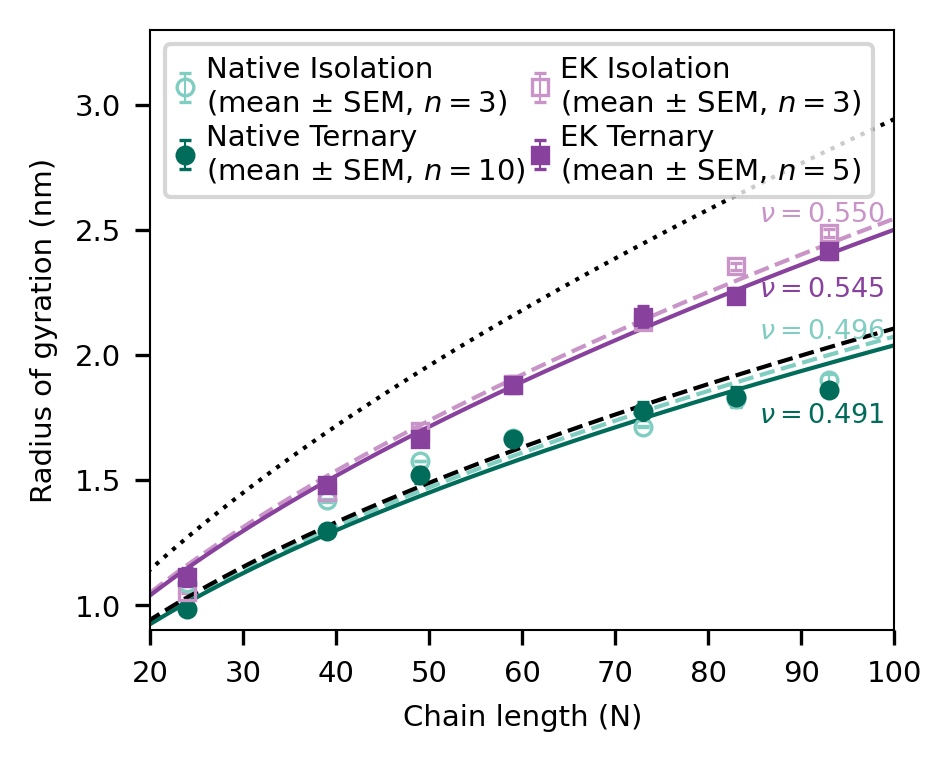

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy import stats


# ==================== 1. Natural 组数据 ====================
# Natural Monomer (3次重复) 
natural_monomer_ang = np.array([
    [4.36,8.53,10.88, 14.09, 15.78, 16.62, 17.12, 17.69, 19.01],
    [4.37,8.5,10.87, 14.27, 15.77, 16.78, 17.16, 18.20, 19.37],
    [4.36,8.46,10.92, 14.21, 15.77, 16.69, 17.13, 18.85, 18.63]
])
# Natural Trenary (10次重复)
natural_trenary_ang =  np.array([
    [4.54,7.91,9.86, 13.78, 15.02, 16.62, 16.66, 18.58, 19.30],
    [4.54,7.84,9.99, 12.85, 15.82, 16.09, 17.17, 19.61, 18.97],
    [4.56,7.88,9.77, 12.84, 15.00, 16.89, 16.21, 19.57, 18.01],
    [4.59,8.02,9.91, 13.05, 17.61, 16.39, 20.11, 17.68, 19.16],
    [4.61,8.01,9.93, 12.14, 15.27, 15.92, 18.45, 18.81, 18.89],
    [4.58,7.86,9.88, 14.17, 14.82, 16.47, 18.53, 17.10, 17.69],
    [4.66,8,9.63, 13.57, 14.83, 17.95, 17.40, 16.74, 17.28],
    [4.58,7.81,9.67, 12.23, 14.62, 16.49, 18.05, 16.89, 18.69],
    [4.62,8.16,9.69, 12.04, 15.08, 16.51, 17.85, 18.13, 19.06],
    [4.65,7.91,10.03, 13.15, 13.87, 16.88, 17.19, 20.12, 19.02]
])
N_natural = np.array([ 6,15,24, 39, 49, 59, 73, 83, 93])  # 链长

# 转换为 nm
natural_monomer_nm = natural_monomer_ang / 10.0
natural_trenary_nm = natural_trenary_ang / 10.0

# 计算均值和标准误
natural_monomer_mean = np.mean(natural_monomer_nm, axis=0)
natural_monomer_sem = np.std(natural_monomer_nm, axis=0, ddof=1) / np.sqrt(3)

natural_trenary_mean = np.mean(natural_trenary_nm, axis=0)
natural_trenary_sem = np.std(natural_trenary_nm, axis=0, ddof=1) / np.sqrt(10)

# ==================== 2. Synthetic 组数据 ====================
# Synthetic Monomer (3次重复) 
synthetic_monomer_ang = np.array([
    [10.49, 14.53, 16.80, 18.95, 21.51, 23.82, 25.11],
    [10.48, 14.57, 17.14, 18.66, 21.12, 23.42, 24.58],
    [10.61, 14.49, 16.97, 18.89, 21.33, 23.38, 24.94]
])
# Synthetic Trenary (5次重复)
synthetic_trenary_ang = np.array([
    [10.81, 14.19, 16.47, 19.09, 21.06, 23.18, 24.91],
    [10.65, 14.72, 16.56, 18.75, 21.41, 22.32, 24.32],
    [10.89, 14.48, 17.37, 18.31, 20.36, 21.70, 24.82],
    [12.61, 14.81, 16.70, 19.98, 22.05, 22.90, 23.28],
    [10.66, 15.82, 16.19, 17.93, 22.77, 21.75, 23.44]
])
N_synthetic = np.array([24, 39, 49, 59, 73, 83, 93])

synthetic_monomer_nm = synthetic_monomer_ang / 10.0
synthetic_trenary_nm = synthetic_trenary_ang / 10.0

synthetic_monomer_mean = np.mean(synthetic_monomer_nm, axis=0)
synthetic_monomer_sem = np.std(synthetic_monomer_nm, axis=0, ddof=1) / np.sqrt(3)

synthetic_trenary_mean = np.mean(synthetic_trenary_nm, axis=0)
synthetic_trenary_sem = np.std(synthetic_trenary_nm, axis=0, ddof=1) / np.sqrt(5)

# ==================== 3. 拟合函数 ====================
b = 0.38   # nm
lp = 0.35  # nm
def polymer_Rg(N, nu):
    prefactor = np.sqrt((2 * lp * b) / ((2 * nu + 1) * (2 * nu + 2)))
    return prefactor * (N ** nu)

# 分别拟合四组数据
# Natural Monomer
popt_nm, _ = curve_fit(polymer_Rg, N_natural, natural_monomer_mean, p0=[0.5])
nu_nm = popt_nm[0]
# Natural Trenary
popt_nt, _ = curve_fit(polymer_Rg, N_natural, natural_trenary_mean, p0=[0.5])
nu_nt = popt_nt[0]
# Synthetic Monomer
popt_sm, _ = curve_fit(polymer_Rg, N_synthetic, synthetic_monomer_mean, p0=[0.5])
nu_sm = popt_sm[0]
# Synthetic Trenary
popt_st, _ = curve_fit(polymer_Rg, N_synthetic, synthetic_trenary_mean, p0=[0.5])
nu_st = popt_st[0]


# ==================== 4. 绘图 ====================
N_plot = np.linspace(0, 100, 300)
Rg_theta = polymer_Rg(N_plot, 0.5)
Rg_saw = polymer_Rg(N_plot, 0.588)

fig, ax = plt.subplots(figsize=(3.2, 2.6), dpi=300)

# ---- Natural 组  ----
ax.errorbar(N_natural, natural_monomer_mean, yerr=natural_monomer_sem,
            fmt='o', color='#80cdc1', markerfacecolor='none',
            markeredgecolor='#80cdc1', markeredgewidth=0.8,
            capsize=1.5, elinewidth=0.5, markersize=4,
            label=f'Native Isolation\n(mean $\\pm$ SEM, $n=3$)') 

ax.errorbar(N_natural, natural_trenary_mean, yerr=natural_trenary_sem,
            fmt='o', color='#016c59', markerfacecolor='#016c59',
            markeredgecolor='#016c59', markeredgewidth=0.8,
            capsize=1.5, elinewidth=0.5, markersize=4,
            label=f'Native Ternary\n(mean $\\pm$ SEM, $n=10$)')

ax.plot(N_plot, polymer_Rg(N_plot, nu_nm), color='#80cdc1', linestyle='--', linewidth=1)
ax.plot(N_plot, polymer_Rg(N_plot, nu_nt), color='#016c59', linestyle='-', linewidth=1)

# ---- Synthetic 组  ----
ax.errorbar(N_synthetic, synthetic_monomer_mean, yerr=synthetic_monomer_sem,
            fmt='s', color='#c994c7', markerfacecolor='none',
            markeredgecolor='#c994c7', markeredgewidth=0.8,
            capsize=1.5, elinewidth=0.5, markersize=4,
            label=f'EK Isolation\n(mean $\\pm$ SEM, $n=3$)') 

ax.errorbar(N_synthetic, synthetic_trenary_mean, yerr=synthetic_trenary_sem,
            fmt='s', color='#88419d', markerfacecolor='#88419d',
            markeredgecolor='#88419d', markeredgewidth=0.8,
            capsize=1.5, elinewidth=0.5, markersize=4,
            label=f'EK Ternary\n(mean $\\pm$ SEM, $n=5$)') 

ax.plot(N_plot, polymer_Rg(N_plot, nu_sm), color='#c994c7', linestyle='--', linewidth=1)
ax.plot(N_plot, polymer_Rg(N_plot, nu_st), color='#88419d', linestyle='-', linewidth=1)


# ---- 理论曲线 ----
ax.plot(N_plot, Rg_theta, 'k--', linewidth=1)
ax.plot(N_plot, Rg_saw, 'k:', linewidth=1 )
N_label = 97
offset_x = 2.0

offsets = {
    'nm': 0.05,   # Natural Monomer (浅绿) 向上
    'nt': -0.25,  # Natural Trenary (深绿) 向下
    'sm': 0.06,   # Synthetic Monomer (浅紫) 更向上
    'st': -0.2,  # Synthetic Trenary (深紫) 更向下
}

# Natural Monomer
Rg_nm_end = polymer_Rg(N_label, nu_nm)
ax.text(N_label + offset_x, Rg_nm_end + offsets['nm'],
        rf'$\nu={nu_nm:.3f}$', color='#80cdc1', fontsize=6.5,
        ha='right', va='center', zorder=5)

# Natural Trenary
Rg_nt_end = polymer_Rg(N_label, nu_nt)
ax.text(N_label + offset_x, Rg_nt_end + offsets['nt'],
        rf'$\nu={nu_nt:.3f}$', color='#016c59', fontsize=6.5,
        ha='right', va='center', zorder=5)

# Synthetic Monomer
Rg_sm_end = polymer_Rg(N_label, nu_sm)
ax.text(N_label + offset_x, Rg_sm_end + offsets['sm'],
        rf'$\nu={nu_sm:.3f}$', color='#c994c7', fontsize=6.5,
        ha='right', va='center', zorder=5)

# Synthetic Trenary
Rg_st_end = polymer_Rg(N_label, nu_st)
ax.text(N_label + offset_x, Rg_st_end + offsets['st'],
        rf'$\nu={nu_st:.3f}$', color='#88419d', fontsize=6.5,
        ha='right', va='center', zorder=5)


# 图形装饰
ax.set_xlabel('Chain length (N)')
ax.set_ylabel('Radius of gyration (nm)')

plt.xlim(20, 100)
plt.ylim(0.9, 3.3)


ax.legend(loc='upper left',  ncol=2, frameon=True, fancybox=True,
          handlelength=0.6, handletextpad=0.4, columnspacing=0.2,labelspacing=0.2)      # 去掉边框)


plt.savefig('Rg_combined.png',
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

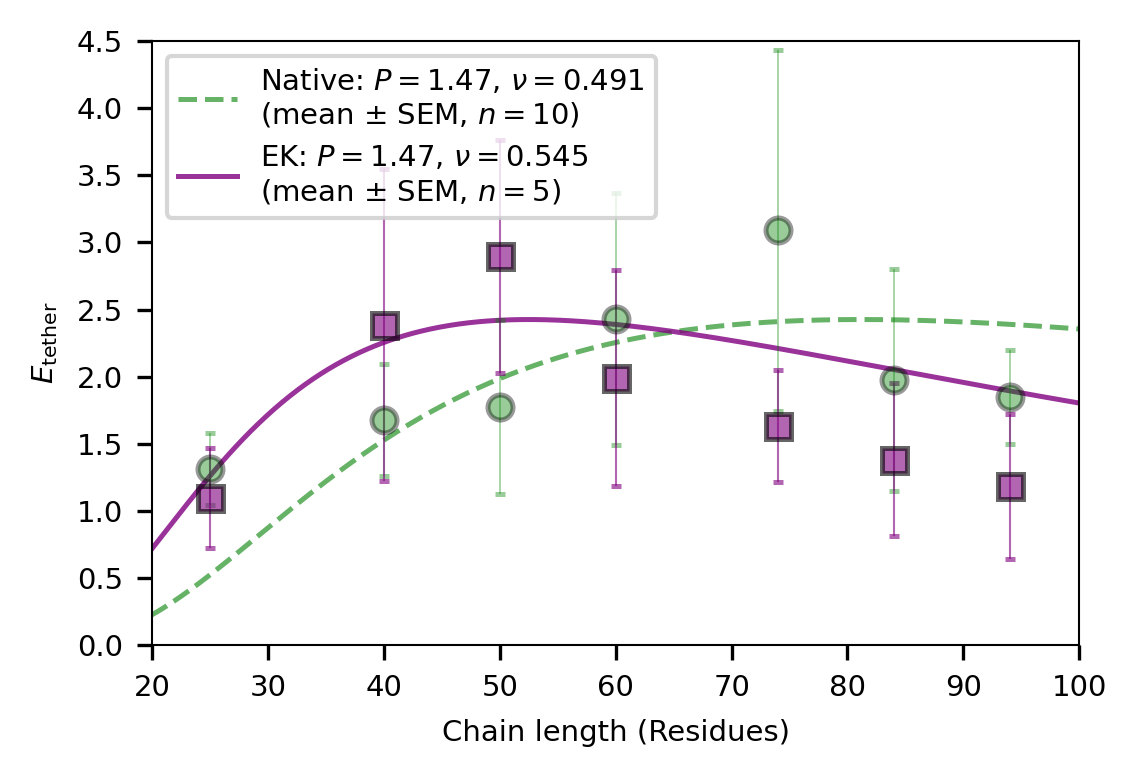

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# ========== 1. Natural IDR 数据 (10次重复) ==========
Ceff_natural_replicates = np.array([
    [0.0817, 1.0481, 0.4303, 3.1538, 0.5409, 0.5962, 1.6731, 0.3726, 7.7284, 0.4760],  # N=7
    [2.5288, 1.6274, 2.0865, 0.6202, 0.2043, 0.0889, 3.0673, 0.0192, 0.3870, 3.2596],  # N=16
    [0.4014, 1.7139, 0.4639, 0.3221, 2.1851, 2.0745, 1.7380, 1.2260, 2.5505, 0.4543],  # N=25
    [0.4543, 3.0697, 0.4784, 2.1106, 0.6202, 1.7067, 0,      1.5264, 3.9856, 2.8173],  # N=40
    [0.1538, 0.1634, 1.5577, 0,      2.2740, 2.9111, 0.5962, 2.4207, 0.8558, 6.8197],  # N=50
    [0.2981, 0.0072, 0.0865, 5.5817, 2.1755, 2.0938, 0.0553, 7.2139, 0,      6.7668],  # N=60
    [6.1178, 0.9856, 13.8365,0,      4.2981, 2.4303, 1.625,  1.1370, 0.2284, 0.2404],  # N=74
    [1.3462, 1.3774, 0.4014, 0.4543, 1.9639, 6.1298, 7.4135, 0.3726, 0.1490, 0.1346],  # N=84
    [2.3317, 1.8486, 1.6298, 0.5072, 1.6683, 4.2716, 2.5769, 2.0553, 1.1322, 0.4423],  # N=94
])
N_natural = np.array([7, 16, 25, 40, 50, 60, 74, 84, 94])

mean_natural = np.mean(Ceff_natural_replicates, axis=1)
std_natural  = np.std (Ceff_natural_replicates, axis=1, ddof=1)
sem_natural  = std_natural / np.sqrt(10)

# ========== 2. Synthetic IDR 数据 (5次重复) ==========
Ceff_synthetic_replicates = np.array([
    [0.0385, 1.6106, 0.5793, 2.1755, 1.0769],  # N=25
    [6.3701, 1.6538, 0.0361, 0.4135, 3.4399],  # N=40
    [2.2163, 4.4230, 0.8629, 1.5649, 5.411 ],  # N=50
    [1.1466, 1.9855, 1.1851, 0.5625, 5.0673],  # N=60
    [1.1947, 2.5841, 0.4976, 2.6298, 1.2548],  # N=74
    [0.6802, 0.7957, 1.3655, 0.4856, 3.5841],  # N=84
    [1.15,   1.3293, 3.1130, 0.3197, 0     ],  # N=94
])
N_synthetic = np.array([25, 40, 50, 60, 74, 84, 94])

mean_synthetic = np.mean(Ceff_synthetic_replicates, axis=1)
std_synthetic  = np.std (Ceff_synthetic_replicates, axis=1, ddof=1)
sem_synthetic  = std_synthetic / np.sqrt(5)

# ========== 3. 理论曲线参数 ==========
NA   = 6.02214076e23
pref = (3.0 / (2.0 * np.pi))**1.5
d        = 4.2       # 接触距离 (nm)
p_theory = 1.47      # 价态因子

# Natural IDR 参数（保留你原值，不修改）
c_natural   = 0.485
nu_natural  = 0.491

# Synthetic IDR 参数（保留你原值，不修改）
c_synthetic   = 0.485
nu_synthetic  = 0.545

def C_polymer(N, c, nu, p):
    N = np.asarray(N, dtype=float)
    r_nm  = c * (N**nu)
    vol_L = (r_nm * 1e-9)**3 * 1000.0
    C0    = (1.0 / (NA * vol_L)) * pref
    return 1000.0 * p * C0 * np.exp(-3.0 * d*d / (2.0 * r_nm * r_nm))

# 计算理论曲线
N_grid = np.linspace(1, 200, 1200)
C_natural_theory   = C_polymer(N_grid, c_natural,   nu_natural,   p_theory)
C_synthetic_theory = C_polymer(N_grid, c_synthetic, nu_synthetic, p_theory)

# ========== 4. 绘图 ==========
fig, ax = plt.subplots(figsize=(3.8, 2.6), dpi=300)

# Natural IDR 实验数据 (绿色圆形)
ax.errorbar(N_natural, mean_natural, yerr=sem_natural,
            fmt='o', color='green', ecolor='green',
            elinewidth=0.4, capsize=1.2, alpha=0.4,
            markersize=6, markeredgecolor='black', markeredgewidth=1.2,
            zorder=5, label='_nolegend_')

# Synthetic IDR 实验数据 (紫色方形)
ax.errorbar(N_synthetic, mean_synthetic, yerr=sem_synthetic,
            fmt='s', color='purple', ecolor='purple',
            elinewidth=0.5, capsize=1.2, alpha=0.6,
            markersize=6, markeredgecolor='black', markeredgewidth=1.2,
            zorder=5, label='_nolegend_')

# 理论曲线
ax.plot(N_grid, C_natural_theory, lw=1.2, color='green',
        linestyle='--', alpha=0.6,
        label=(rf'Native: $P={p_theory}$, $\nu={nu_natural}$'
               '\n(mean $\\pm$ SEM, $n=10$)'),
        zorder=2)

ax.plot(N_grid, C_synthetic_theory, lw=1.2, color='purple',
        linestyle='-', alpha=0.8,
        label=(rf'EK: $P={p_theory}$, $\nu={nu_synthetic}$'
               '\n(mean $\\pm$ SEM, $n=5$)'),
        zorder=2)

# 图表设置
plt.xlabel('Chain length (Residues)')
plt.ylabel(r'$\mathit{E}_{\mathrm{tether}}$')
plt.xlim(20, 100)
plt.ylim(0, 4.5)
plt.legend(loc='upper left', bbox_to_anchor=(0, 1.0))
plt.tight_layout()
plt.savefig('IDR_combined_p1.47.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()


In [37]:
##fig6

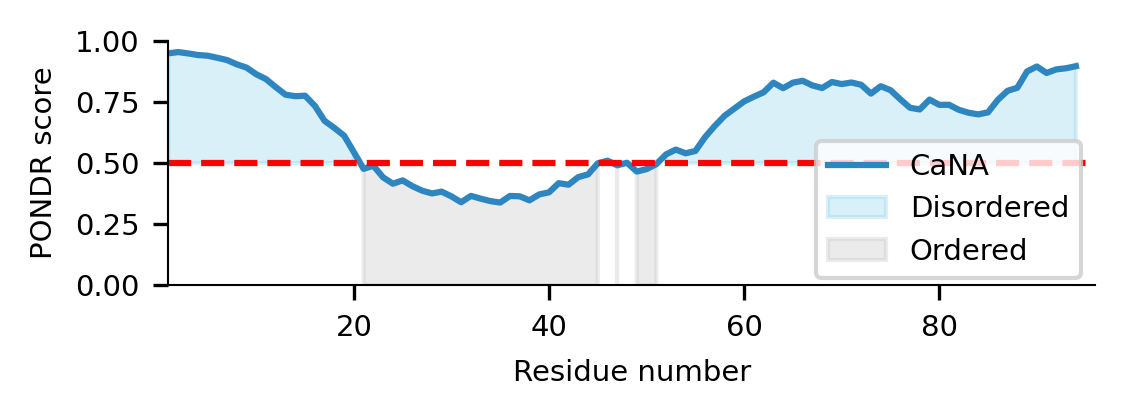

In [38]:
import matplotlib.pyplot as plt
import numpy as np

positions = list(range(1, 95))
scores = [
    0.9495, 0.9546, 0.9492, 0.9427, 0.9399, 0.9313, 0.9219, 0.9046, 0.8910, 0.8638,
    0.8439, 0.8109, 0.7801, 0.7739, 0.7760, 0.7347, 0.6729, 0.6441, 0.6123, 0.5450,
    0.4763, 0.4892, 0.4415, 0.4156, 0.4291, 0.4054, 0.3870, 0.3758, 0.3830, 0.3637,
    0.3397, 0.3657, 0.3543, 0.3443, 0.3383, 0.3654, 0.3640, 0.3473, 0.3717, 0.3801,
    0.4178, 0.4114, 0.4426, 0.4536, 0.4990, 0.5099, 0.4910, 0.5013, 0.4652, 0.4752,
    0.4957, 0.5357, 0.5553, 0.5401, 0.5495, 0.6064, 0.6525, 0.6939, 0.7233, 0.7526,
    0.7721, 0.7900, 0.8292, 0.8067, 0.8294, 0.8370, 0.8180, 0.8074, 0.8320, 0.8236,
    0.8301, 0.8206, 0.7846, 0.8149, 0.7987, 0.7616, 0.7265, 0.7197, 0.7601, 0.7385,
    0.7387, 0.7183, 0.7062, 0.6994, 0.7078, 0.7589, 0.7960, 0.8084, 0.8754, 0.8955,
    0.8691, 0.8838, 0.8884, 0.8969 
]

# 绘制图形
plt.figure(figsize=(3.7, 1.4),dpi=300)
plt.plot(positions, scores, '#2E86C1', linewidth=1.5, label='CaNA')
plt.axhline(y=0.5, color='r', linestyle='--', linewidth=1.5)
plt.fill_between(positions, 0.5, scores, where=(np.array(scores) >= 0.5), color='skyblue', alpha=0.3, label='Disordered')
plt.fill_between(positions, 0.0, scores, where=(np.array(scores) < 0.5), color='silver', alpha=0.3, label='Ordered')
plt.xlabel('Residue number')
plt.ylabel('PONDR score')
#plt.title('Protein Disorder Prediction by AIUPred')
plt.ylim(0, 1.0)
plt.xlim(1, 96)



# 设置边框和刻度样式
ax = plt.gca()

# 移除上边框和右边框
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)


plt.legend(loc='upper right', bbox_to_anchor=(1.0, 0.65),  ncol=1)
plt.tight_layout()

plt.savefig('can-linker-idr.png', dpi=300, bbox_inches='tight', 
            transparent=True)
plt.show()

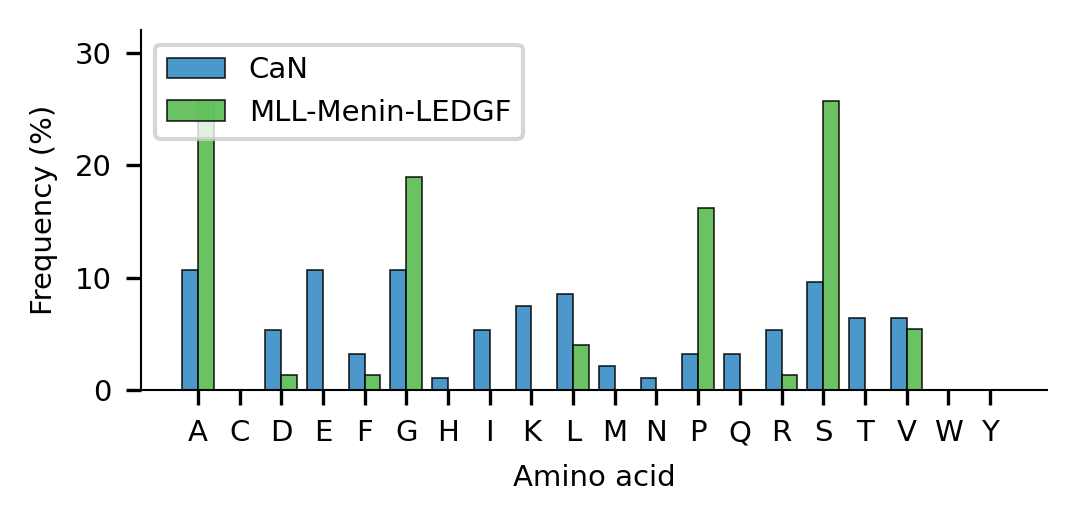

In [39]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# ================= 序列 =================
seq1 = "SDDELGSEEDGFDGATAAARKEVIRNKIRAIGKMARVFSVLREESESVLTLKGLTPTGMLPSGVLSGGKQTLQSATVEAIEADEAIKGFSPQHK"
seq2 = "LPPGPPVGGGGPGAPPSPPAVAAAAAAAGSSGAGVPGGAAAASAASSSSASSSSSSSSSASSGPALLRVGPGFD"

name1 = "CaN"
name2 = "MLL-Menin-LEDGF"

# 标准 20 种氨基酸顺序
amino_acids = list("ACDEFGHIKLMNPQRSTVWY")

# ================= 统计 =================
count1 = Counter(seq1)
count2 = Counter(seq2)
len1, len2 = len(seq1), len(seq2)

values1 = np.array([count1.get(aa, 0) / len1 * 100 for aa in amino_acids])
values2 = np.array([count2.get(aa, 0) / len2 * 100 for aa in amino_acids])



# ================= 绘图 =================
fig, ax = plt.subplots(figsize=(3.6, 1.75), dpi=300)

x = np.arange(len(amino_acids))
width = 0.38

bars1 = ax.bar(x - width/2, values1, width,
               color='#2E86C1', edgecolor='black', linewidth=0.4,
               alpha=0.85, label=name1)

bars2 = ax.bar(x + width/2, values2, width,
               color='#50B848', edgecolor='black', linewidth=0.4,
               alpha=0.85, label=name2)

# ================= 坐标轴 =================
ax.set_xticks(x)
ax.set_xticklabels(amino_acids)
ax.set_xlabel('Amino acid')
ax.set_ylabel('Frequency (%)')

ymax = max(values1.max(), values2.max())
ax.set_ylim(0, np.ceil(ymax / 5) * 5 + 2)

# 设置边框和刻度样式
ax = plt.gca()

# 移除上边框和右边框
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)


# 图例
ax.legend(loc='upper left')

plt.tight_layout()

# 保存
plt.savefig('amino_acid_composition_comparison.png',
            dpi=300, bbox_inches='tight', transparent=True)

plt.show()

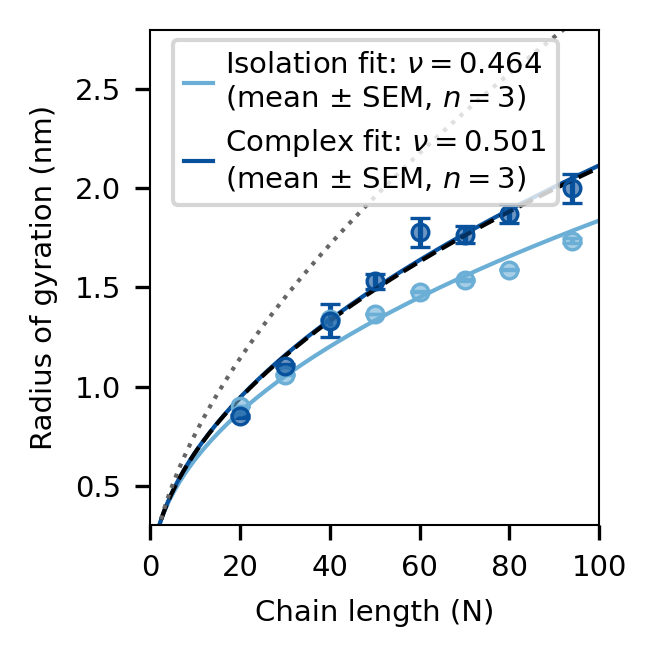

In [40]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy import stats



# 1. 输入原始数据 (单位: Å)

# Trenary: 3次重复, 8个链长
trenary_data_angstrom = np.array([
    #20,30,40,50,60,70,80,94
    [8.63,11.1,12.92,15.02,18.6,18.25,18.69,21.47],
    [8.39,10.9,12.11,14.88,18.43,17.91,17.95,19.29],
    [8.47,11.14,14.91,16.07,16.31,16.82,19.55,19.29],
])

# Monomer: 3次重复, 8个链长
monomer_data_angstrom = np.array([
    [9.04,10.67,13.41,13.70,14.75,15.45,15.93,17.3],
    [8.99,10.54,13.41,13.64,14.80,15.37,15.97,17.59],
    [9.04,10.60,13.41,13.66,14.84,15.33,15.82,17.18]
])

# 链长 (氨基酸数)
N = np.array([20,30,40,50,60,70,80,94])

# 转换单位: Å -> nm
trenary_data_nm = trenary_data_angstrom / 10.0
monomer_data_nm = monomer_data_angstrom / 10.0

# 2. 计算每个链长的平均值和标准差

# Trenary (n=3)
trenary_mean = np.mean(trenary_data_nm, axis=0)
trenary_std = np.std(trenary_data_nm, axis=0, ddof=1)   # 样本标准差
trenary_sem = trenary_std / np.sqrt(3)                  # 标准误

# Monomer (n=3)
monomer_mean = np.mean(monomer_data_nm, axis=0)
monomer_std = np.std(monomer_data_nm, axis=0, ddof=1)
monomer_sem = monomer_std / np.sqrt(3)


# 3. 常数
b = 0.38   # nm 单体长度（Kuhn长度）
lp = 0.35  # nm

def polymer_Rg(N, nu):
    prefactor = np.sqrt((2 * lp * b) / ((2 * nu + 1) * (2 * nu + 2)))
    return prefactor * (N ** nu)


popt1, pcov1 = curve_fit(polymer_Rg, N, trenary_mean, p0=[0.5])
nu_fit1 = popt1[0]
nu_std1 = np.sqrt(np.diag(pcov1))[0]

popt2, pcov2 = curve_fit(polymer_Rg, N, monomer_mean, p0=[0.5])
nu_fit2 = popt2[0]
nu_std2 = np.sqrt(np.diag(pcov2))[0]



#与理论值比较 
nu_theta = 0.5
nu_saw = 0.588

# Trenary
z_theta1 = (nu_fit1 - nu_theta) / nu_std1
z_saw1 = (nu_fit1 - nu_saw) / nu_std1
p_theta1 = 2 * (1 - stats.norm.cdf(abs(z_theta1)))
p_saw1 = 2 * (1 - stats.norm.cdf(abs(z_saw1)))

# Monomer
z_theta2 = (nu_fit2 - nu_theta) / nu_std2
z_saw2 = (nu_fit2 - nu_saw) / nu_std2
p_theta2 = 2 * (1 - stats.norm.cdf(abs(z_theta2)))
p_saw2 = 2 * (1 - stats.norm.cdf(abs(z_saw2)))



N_plot = np.linspace(0, 100, 200)

# 拟合曲线
Rg_fit1 = polymer_Rg(N_plot, nu_fit1)   # Trenary / Complex
Rg_fit2 = polymer_Rg(N_plot, nu_fit2)   # Monomer

# 理论曲线
Rg_theta = polymer_Rg(N_plot, nu_theta)
Rg_saw = polymer_Rg(N_plot, nu_saw)

plt.figure(figsize=(2.2, 2.2), dpi=300)

# Monomer (浅蓝)
plt.errorbar(N, monomer_mean, yerr=monomer_sem,
             fmt='o', color='#6baed6',
             markerfacecolor=(0.420, 0.682, 0.839, 0.6),
             markeredgecolor='#6baed6', markeredgewidth=0.8,
             capsize=2.5, elinewidth=1.25, markersize=4)

# Trenary (深蓝)
plt.errorbar(N, trenary_mean, yerr=trenary_sem,
             fmt='o', color='#08519c',
             markerfacecolor=(0.031, 0.318, 0.612, 0.6),
             markeredgecolor='#08519c', markeredgewidth=0.8,
             capsize=2.5, elinewidth=1.25, markersize=4)

# 拟合曲线（ν 用 \mathit 显式斜体；数字因全局 STIX 自动为 Times 风格）
plt.plot(N_plot, Rg_fit2, color='#6baed6', linestyle='-', linewidth=1,
         label=f'Isolation fit: $\\nu={nu_fit2:.3f}$\n(mean $\\pm$ SEM, $n=3$)')

plt.plot(N_plot, Rg_fit1, color='#08519c', linestyle='-', linewidth=1,
         label=f'Complex fit: $\\nu={nu_fit1:.3f}$\n(mean $\\pm$ SEM, $n=3$)') 

# 理论曲线
plt.plot(N_plot, Rg_theta, color='black', linestyle='--', linewidth=1)
plt.plot(N_plot, Rg_saw, color='#666666', linestyle=':', linewidth=1)

# 图形装饰
plt.xlabel('Chain length (N)')
plt.ylabel('Radius of gyration (nm)')

plt.legend(loc='upper right', bbox_to_anchor=(0.94, 1.01),frameon=True, fancybox=True,
          handlelength=1, handletextpad=0.4, columnspacing=0.4)

plt.xlim(0, 100)
plt.ylim(0.3, 2.8)

plt.tight_layout()
plt.savefig('nu_rog_nat.png', dpi=300, transparent=True)
plt.show()

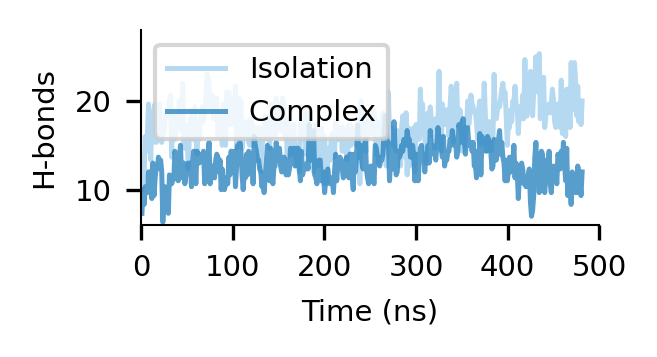

In [7]:
import numpy as np
import matplotlib.pyplot as plt


# 加载数据
hbond1 = np.loadtxt("/home/jhsong/CaN-project/amber/anlysis/complex/IDR-inter.dat")
hbond2 = np.loadtxt("/home/jhsong/CaN-project/amber/anlysis/complex/IDR-inter2.dat")
hbond22 = np.loadtxt("/home/jhsong/CaN-project/amber/anlysis/complex/IDR-inter3.dat")

hbond3 = np.loadtxt("/home/jhsong/CaN-project/amber/anlysis/complex/hbond1.dat")
hbond4 = np.loadtxt("/home/jhsong/CaN-project/amber/anlysis/complex/hbond2.dat")
hbond44 = np.loadtxt("/home/jhsong/CaN-project/amber/anlysis/complex/hbond3.dat")

hbond5 = np.loadtxt("/home/jhsong/CaN-project/amber/anlysis/monomer/hbond1-inter.dat")
hbond6 = np.loadtxt("/home/jhsong/CaN-project/amber/anlysis/monomer/hbond2-inter.dat")
hbond7 = np.loadtxt("/home/jhsong/CaN-project/amber/anlysis/monomer/hbond3-inter.dat")

hbond_complex1 = (hbond1[:, 1] + hbond2[:, 1]+ hbond22[:, 1]) / 3
hbond_complex2 = (hbond3[:, 1] + hbond4[:, 1]+ hbond44[:, 1]) / 3
hbond_complex3 = (hbond5[:, 1] + hbond6[:, 1] + hbond7[:, 1]) / 3

fig, ax = plt.subplots(figsize=(2.2, 1.2), dpi=300)

# 使用折线图

ax.plot(hbond6[:, 0] * 1.2, hbond_complex3,   
        color='#85C1E9', linewidth=1.2, alpha=0.6, label='Isolation')

ax.plot(hbond1[:, 0] * 1.2, hbond_complex1,   
        color='#2E86C1', linewidth=1.2, alpha=0.8, label='Complex')


# 坐标轴设置
ax.set_xlabel('Time (ns)')
ax.set_ylabel('H-bonds')
ax.set_ylim(6, 28)
ax.set_xlim(0, 500)


ax.legend(loc='upper left')

# 设置边框和刻度样式 
ax = plt.gca()


# 移除上边框和右边框
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.grid(False)
plt.tight_layout()

plt.savefig('H-bonds-vs2.png', dpi=300, bbox_inches='tight', 
            transparent=True)
plt.show()

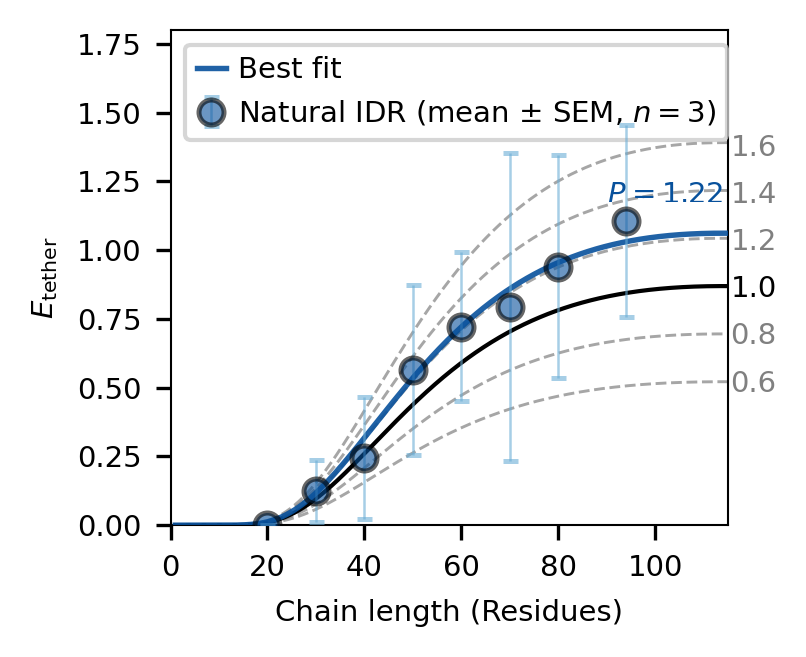

In [42]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from sklearn.metrics import mean_squared_error

# 1. 输入：E_tether = P_tethered / P_untethered

E_tether_replicates = np.array([
    [0,       0,       0      ],   # N=20
    [0.0049,  0.0146,  0.3495 ],   # N=30
    [0.0436,  0,       0.6893 ],   # N=40
    [0.0777,  0.4806,  1.1359 ],   # N=50
    [0.9514,  1.0291,  0.1844 ],   # N=60
    [1.8738,  0,       0.5049 ],   # N=70
    [1.4029,  1.2864,  0.1310 ],   # N=80
    [0.5097,  1.0873,  1.7184 ],   # N=94
])
N_exp = np.array([20, 30, 40, 50, 60, 70, 80, 94], dtype=float)
P_untethered = 0.0206
n_reps = E_tether_replicates.shape[1]   # ★ 自动取重复次数

# ---- 统计量 ----
E_mean = np.mean(E_tether_replicates, axis=1)
E_std  = np.std (E_tether_replicates, axis=1, ddof=1)
E_sem  = E_std / np.sqrt(n_reps)



# 2. 物理参数（CaN 系统）
nu = 0.501   # Flory 指数（CaN 完整系统）
d  = 5.2     # nm，拴系点到结合位点
c  = 0.485   # nm，统计段长

A0_mM = 1660.0 * (3.0 / (2.0 * np.pi))**1.5 * c**(-3.0)

# 3. 无量纲核函数 f(N)
def f_N(N):
    N = np.asarray(N, dtype=float)
    return N**(-3.0 * nu) * np.exp(-1.5 * (d / c)**2 * N**(-2.0 * nu))

# 4. 模型
def model_P(N, P):
    return P * A0_mM * f_N(N)

# 5. 拟合 P
mask_fit  = N_exp > 7
fit_label = "N > 7"          

N_fit = N_exp[mask_fit]
E_fit = E_mean[mask_fit]

# 解析解
B_analytic = np.sum(E_fit * f_N(N_fit)) / np.sum(f_N(N_fit)**2)
P_analytic = B_analytic / A0_mM

# curve_fit
popt, pcov = curve_fit(model_P, N_fit, E_fit, p0=[P_analytic])
P_fit = popt[0]
P_std = np.sqrt(np.diag(pcov))[0]

# 全点拟合对照
popt_all, pcov_all = curve_fit(model_P, N_exp, E_mean, p0=[P_analytic])
P_all     = popt_all[0]
P_all_std = np.sqrt(np.diag(pcov_all))[0]

# RMSE
rmse_fit = np.sqrt(mean_squared_error(E_fit, model_P(N_fit, P_fit)))
rmse_all = np.sqrt(mean_squared_error(E_mean, model_P(N_exp, P_all)))


# ================================================================
# 6. 绘图
# ================================================================
N_grid = np.linspace(1, 200, 1200)
P_values = [0.6, 0.8, 1.0, 1.2, 1.4, 1.6]

plt.figure(figsize=(2.7, 2.2), dpi=300)

# ---- 绘制不同 P 值的理论曲线 ----
for P in P_values:
    y_grid = model_P(N_grid, P)

    if P == 1.0:
        color, ls, lw, alpha = 'black', '-',  1.0, 1.00
    else:
        color, ls, lw, alpha = 'gray',  '--', 0.7, 0.70

    plt.plot(N_grid, y_grid, lw=lw, color=color, linestyle=ls,
             alpha=alpha, zorder=2)

    # ★ 曲线右端 P 值标签
    y_lab = model_P(100, P)
    lab_color = 'black' if P == 1.0 else color
    plt.text(115.5, y_lab, f'{P:.1f}', fontsize=7, color=lab_color,
             va='center', ha='left', zorder=10, clip_on=False)

# ---- 数据点 + SEM 误差棒 ----
plt.errorbar(N_exp, E_mean, yerr=E_sem,
             fmt='o', color='#08519c', ecolor='#6baed6',
             elinewidth=0.6, capsize=1.8, alpha=0.6,
             markersize=6, markeredgecolor='black', markeredgewidth=1.2,
             label=rf'Natural IDR (mean $\pm$ SEM, $n={n_reps}$)', zorder=10)

# ---- 最优 P 曲线 ----
plt.plot(N_grid, model_P(N_grid, P_fit),
         lw=1.3, color='#08519c', linestyle='-', alpha=0.9,
         label=rf'Best fit', zorder=8)   

# ---- 单独文本：P_best ----
x_text = 90
y_text = model_P(x_text, P_fit) + 0.15   

plt.text(x_text, y_text,
         rf'$P_{{\mathrm{{}}}} = {P_fit:.2f}$',
         color='#08519c',
         ha='left', va='bottom', weight='bold', zorder=20)

# ---- 样式 ----
plt.xlabel('Chain length (Residues)')
plt.ylabel(r'$\mathit{E}_{\mathrm{tether}}$')
plt.xlim(0, 115)                          
plt.ylim(0, 1.8)
plt.legend(loc='upper left',frameon=True, fancybox=True,
          handlelength=1, handletextpad=0.4, columnspacing=0.4)

plt.tight_layout()
plt.savefig('P_value_fit.png', dpi=300,
            bbox_inches='tight', transparent=True)
plt.show()



In [44]:
#figs1

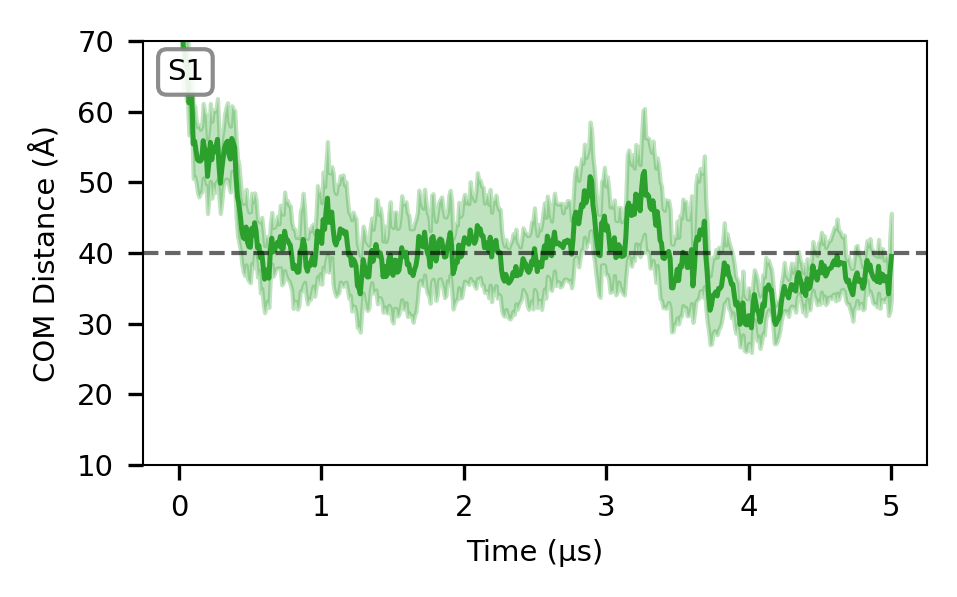

In [45]:
import numpy as np
import matplotlib.pyplot as plt

main_color = '#2ca02c'   # 蓝色

data_files = [
    "/home/jhsong/Menin_MLL_project/Menin-Mll/test-3-gro/11-noidr-M-M-L/GRO/charmm-gui-5396311327/gromacs1/com_groov.xvg",
    "/home/jhsong/Menin_MLL_project/Menin-Mll/test-3-gro/11-noidr-M-M-L/GRO/charmm-gui-5396311327/gromacs2/com_groov.xvg",
    "/home/jhsong/Menin_MLL_project/Menin-Mll/test-3-gro/11-noidr-M-M-L/GRO/charmm-gui-5396311327/gromacs3/com_groov.xvg",
    "/home/jhsong/Menin_MLL_project/Menin-Mll/test-3-gro/11-noidr-M-M-L/GRO/charmm-gui-5396311327/gromacs4/com_groov.xvg",
    "/home/jhsong/Menin_MLL_project/Menin-Mll/test-3-gro/11-noidr-M-M-L/GRO/charmm-gui-5396311327/gromacs5/com_groov.xvg",
    "/home/jhsong/Menin_MLL_project/Menin-Mll/test-3-gro/11-noidr-M-M-L/GRO/charmm-gui-5396311327/gromacs6/com_groov.xvg",
    "/home/jhsong/Menin_MLL_project/Menin-Mll/test-3-gro/11-noidr-M-M-L/GRO/charmm-gui-5396311327/gromacs7/com_groov.xvg",
    "/home/jhsong/Menin_MLL_project/Menin-Mll/test-3-gro/11-noidr-M-M-L/GRO/charmm-gui-5396311327/gromacs8/com_groov.xvg",
    "/home/jhsong/Menin_MLL_project/Menin-Mll/test-3-gro/11-noidr-M-M-L/GRO/charmm-gui-5396311327/gromacs9/com_groov.xvg",
    "/home/jhsong/Menin_MLL_project/Menin-Mll/test-3-gro/11-noidr-M-M-L/GRO/charmm-gui-5396311327/gromacs10/com_groov.xvg"
]

def read_xvg(file_path):
    """返回时间(ns)和距离(Å)的numpy数组"""
    with open(file_path, 'r') as f:
        lines = [line.strip() for line in f if not line.startswith(('#', '@'))]
    data = np.array([list(map(float, line.split())) for line in lines if len(line.split())>=2])
    time_ps = data[:, 0]
    dist_nm = data[:, 1]
    time_ns = time_ps / 1000000.0
    dist_ang = dist_nm * 10.0
    return time_ns, dist_ang

# ================= 读取所有数据 =================
all_times = []
all_dists = []

for f in data_files:
    t, d = read_xvg(f)
    all_times.append(t)
    all_dists.append(d)

# ================= 对齐时间点 =================
t_min = max([t[0] for t in all_times])
t_max = min([t[-1] for t in all_times])
common_t = np.linspace(t_min, t_max, 500)

interp_dists = []
for t, d in zip(all_times, all_dists):
    d_interp = np.interp(common_t, t, d)
    interp_dists.append(d_interp)

distance_matrix = np.column_stack(interp_dists)   # shape (n_points, n_trajs)

# ================= 平均值和标准误差SEe =================
n_trajs = len(data_files)
mean_dist = np.mean(distance_matrix, axis=1)
std_dist = np.std(distance_matrix, axis=1, ddof=1)      # 样本标准差
sem_dist = std_dist / np.sqrt(n_trajs)                  # 标准误差

# ================= 绘图 =================
plt.figure(figsize=(3.2, 2),dpi=300)
ax = plt.gca()

# 主曲线：平均值
ax.plot(common_t, mean_dist, color=main_color, linewidth=1.2, label=f'Mean')
ax.axhline(40, color='black', linestyle='--', linewidth=1, alpha=0.6, label='Ref(16 Å)')

# 阴影：±1 SEM
ax.fill_between(common_t,
                mean_dist - sem_dist,
                mean_dist + sem_dist,
                color=main_color, alpha=0.3, label='mean ± SEM')

# 参考线

# 坐标轴标签
ax.set_xlabel('Time (μs)')
ax.set_ylabel('COM Distance (Å)')

# 设置坐标轴范围
#ax.set_xlim([0, 5])
ax.set_ylim([10, 70])

# 设置刻度和标签 
#ax.set_xticks(np.arange(0, 16, 3))
ax.set_yticks(np.arange(10, 71, 10))
ax.set_xticks([0, 1, 2, 3,4, 5])

# 添加S1标签 
ax.annotate('S1', 
            xy=(0.03, 0.96), 
            xycoords='axes fraction',
            bbox=dict(boxstyle="round,pad=0.3", 
                     facecolor='white', 
                     alpha=0.9, 
                     edgecolor='gray', 
                     linewidth=1),
            ha='left', 
            va='top',
            zorder=10)



plt.tight_layout()
plt.savefig('s1-com', dpi=300, bbox_inches='tight', 
            transparent=True)
plt.show()

In [46]:
##figs2

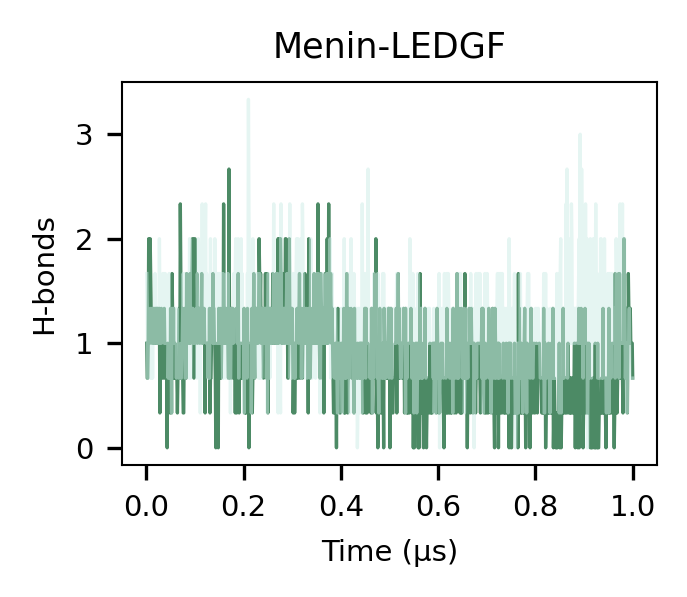

In [47]:
import numpy as np
import matplotlib.pyplot as plt


# 加载数据
hbond1 = np.loadtxt("/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/Trajin/1-M-M-L-noidr/menin-ledgf-hbond.dat")
hbond2 = np.loadtxt("/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/Trajin/1-M-M-L-noidr/menin-ledgf-hbond2.dat")
hbond3 = np.loadtxt("/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/Trajin/1-M-M-L-noidr/menin-ledgf-hbond3.dat")


hbond4 = np.loadtxt("/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/Trajin/6-M-M-L-withidr/menin-ledgf-hbond.dat")
hbond5 = np.loadtxt("/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/Trajin/6-M-M-L-withidr/menin-ledgf-hbond2.dat")
hbond6 = np.loadtxt("/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/Trajin/6-M-M-L-withidr/menin-ledgf-hbond3.dat")




hbond_alone = (hbond1[:, 1]+hbond2[:, 1]+hbond3[:, 1])/3

hbondwith = (hbond4[:, 1] + hbond5[:, 1] + hbond6[:, 1]) / 3


plt.figure(figsize=(2.3, 2), dpi=300)

# 使用折线图
ax = plt.gca()
ax.plot(hbond4[:, 0] * 0.001, hbondwith, 
        color='#005824', linewidth=0.8, alpha=0.7, label='with IDR')
ax.plot(hbond1[:, 0] * 0.001, hbond_alone, 
        color='#ccece6', linewidth=0.8, alpha=0.5, label='no IDR')



# 坐标轴设置
ax.set_xlabel('Time (μs)')
ax.set_ylabel('H-bonds')
#ax.set_ylim(0, 21)
#ax.set_xlim(0,1.02)

ax.set_title(f'Menin-LEDGF')


#ax.legend(loc='upper right')


plt.tight_layout()

plt.savefig('H-bonds-WITH-NOidr-ME-L.png', dpi=300, bbox_inches='tight', 
            transparent=True)
plt.show()

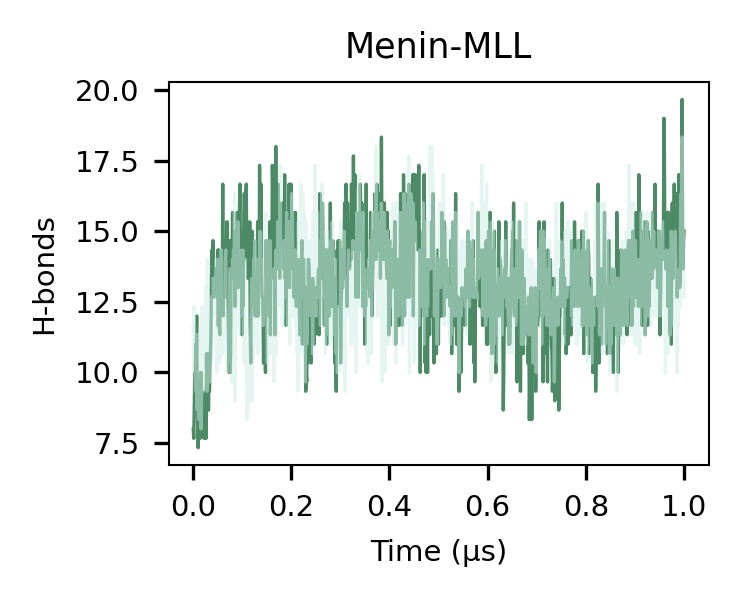

In [48]:
import numpy as np
import matplotlib.pyplot as plt


# 加载数据
hbond1 = np.loadtxt("/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/Trajin/1-M-M-L-noidr/menin-mll-hbond.dat")
hbond2 = np.loadtxt("/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/Trajin/1-M-M-L-noidr/menin-mll-hbond2.dat")
hbond3 = np.loadtxt("/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/Trajin/1-M-M-L-noidr/menin-mll-hbond3.dat")


hbond4 = np.loadtxt("/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/Trajin/6-M-M-L-withidr/menin-mll-hbond.dat")
hbond5 = np.loadtxt("/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/Trajin/6-M-M-L-withidr/menin-mll-hbond2.dat")
hbond6 = np.loadtxt("/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/Trajin/6-M-M-L-withidr/menin-mll-hbond3.dat")




hbond_alone = (hbond1[:, 1]+hbond2[:, 1]+hbond3[:, 1])/3

hbondwith = (hbond4[:, 1] + hbond5[:, 1] + hbond6[:, 1]) / 3


plt.figure(figsize=(2.38, 2), dpi=300)

# 使用折线图
ax = plt.gca()

ax.plot(hbond4[:, 0] * 0.001, hbondwith, 
        color='#005824', linewidth=0.8, alpha=0.7, label='with IDR')
ax.plot(hbond1[:, 0] * 0.001, hbond_alone, 
        color='#ccece6', linewidth=0.8, alpha=0.5, label='no IDR')


# 坐标轴设置
ax.set_xlabel('Time (μs)')
ax.set_ylabel('H-bonds')
#ax.set_ylim(0, 21)
#ax.set_xlim(0,1.02)



#ax.legend(loc='upper right')

ax.set_title(f'Menin-MLL')

plt.tight_layout()

plt.savefig('H-bonds-WITH-NOid-ME-M.png', dpi=300, bbox_inches='tight', 
            transparent=True)
plt.show()

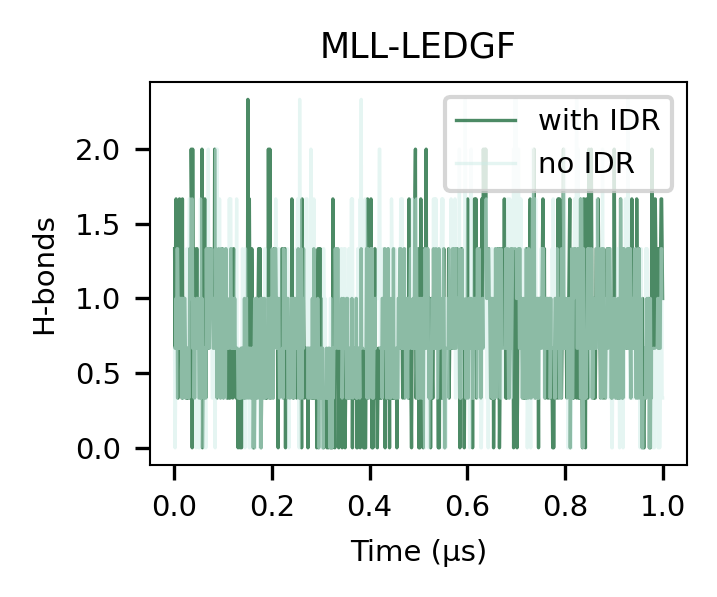

In [49]:
import numpy as np
import matplotlib.pyplot as plt


# 加载数据
hbond1 = np.loadtxt("/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/Trajin/1-M-M-L-noidr/ledgf-mll-hbond.dat")
hbond2 = np.loadtxt("/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/Trajin/1-M-M-L-noidr/ledgf-mll-hbond2.dat")
hbond3 = np.loadtxt("/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/Trajin/1-M-M-L-noidr/ledgf-mll-hbond3.dat")


hbond4 = np.loadtxt("/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/Trajin/6-M-M-L-withidr/mll-ledgf-hbond.dat")
hbond5 = np.loadtxt("/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/Trajin/6-M-M-L-withidr/mll-ledgf-hbond2.dat")
hbond6 = np.loadtxt("/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/Trajin/6-M-M-L-withidr/mll-ledgf-hbond3.dat")




hbond_alone = (hbond1[:, 1]+hbond2[:, 1]+hbond3[:, 1])/3

hbondwith = (hbond4[:, 1] + hbond5[:, 1] + hbond6[:, 1]) / 3


plt.figure(figsize=(2.4, 2), dpi=300)

# 使用折线图
ax = plt.gca()

ax.plot(hbond4[:, 0] * 0.001, hbondwith, 
        color='#005824', linewidth=0.8, alpha=0.7, label='with IDR')
ax.plot(hbond1[:, 0] * 0.001, hbond_alone, 
        color='#ccece6', linewidth=0.8, alpha=0.5, label='no IDR')


# 坐标轴设置
ax.set_xlabel('Time (μs)')
ax.set_ylabel('H-bonds')
#ax.set_ylim(0, 21)
#ax.set_xlim(0,1.02)



ax.legend(loc='upper right')

ax.set_title(f'MLL-LEDGF')

plt.tight_layout()

plt.savefig('H-bonds-WITH-NOidr-mll-led.png', dpi=300, bbox_inches='tight', 
            transparent=True)
plt.show()

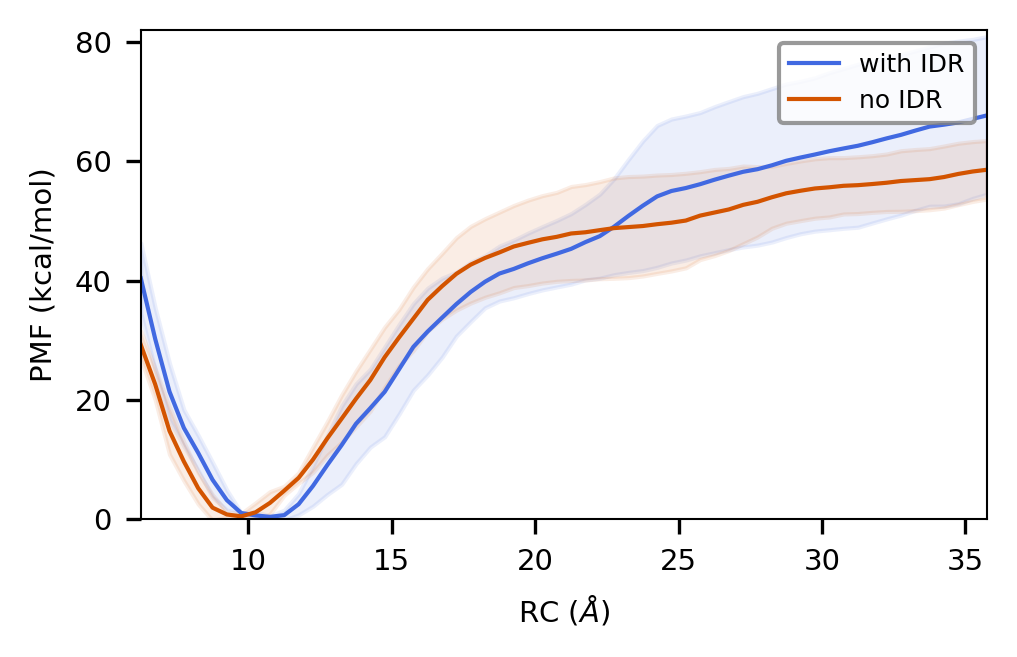

In [51]:
import numpy as np
import matplotlib.pyplot as plt
import os


# =====================================================================
files_with_idr = [
    '/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/6-MLL154/PMF-6/output/result.dat',
    '/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/6-MLL154/PMF-6-2/output/result.dat',
    '/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/6-MLL154/PMF-6-3/output/result.dat',

]
files_no_idr = [
    '/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/1-M-M-L/PMF1/output/result.dat',
    '/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/1-M-M-L/PMF1-2/output/result.dat',
    '/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/1-M-M-L/PMF1-3/output/result.dat',

]


# =====================================================================
def load_pmf_by_bin(files, x_round=3, use_cols=(1,)):
    """
    参数
    ----
    files     : 文件路径列表（
    x_round   : x 值四舍五入的小数位，用于容差分组
    use_cols  : 取哪些列作为 PMF 值。
                
                
    返回
    ----
    ux    : 唯一 x 值
    mean_y: 每个 x bin 的均值
    std_y : 每个 x bin 的 np.std(ddof=0)
    n_y   : 每个 x bin 的 replica 数
    """
    xs, ys = [], []
    for f in files:
        if not os.path.exists(f):
            print(f'[warn] 文件不存在，跳过: {f}')
            continue
        d = np.loadtxt(f, comments='#')
        if d.ndim == 1:
            d = d.reshape(1, -1)
        cols = [0] + list(use_cols)
        m = np.all(np.isfinite(d[:, cols]), axis=1)
        d = d[m, :]
        for c in use_cols:
            xs.append(d[:, 0])
            ys.append(d[:, c])

    if not xs:
        return np.array([]), np.array([]), np.array([]), np.array([])

    x_all = np.concatenate(xs)
    y_all = np.concatenate(ys)

    x_key = np.round(x_all, x_round)
    ux = np.unique(x_key)

    mean_y = np.array([y_all[x_key == x].mean()           for x in ux])
    std_y  = np.array([y_all[x_key == x].std(ddof=0)      for x in ux])  # 总体 std
    n_y    = np.array([np.sum(x_key == x)                 for x in ux])

    return ux, mean_y, std_y, n_y


# 3. 加载两个系统
x1, m1, s1, n1 = load_pmf_by_bin(files_with_idr, x_round=3, use_cols=(1,))
x2, m2, s2, n2 = load_pmf_by_bin(files_no_idr,  x_round=3, use_cols=(1,))



# 4. 绘图 
plt.figure(dpi=300, figsize=(3.4,2.2))

color1 = 'royalblue'   # with IDR
color2 = '#D35400'     # no IDR

plt.fill_between(x1, m1 - s1, m1 + s1,
                 alpha=0.1, color=color1, label='_nolegend_')
plt.fill_between(x2, m2 - s2, m2 + s2,
                 alpha=0.1, color=color2, label='_nolegend_')

plt.plot(x1, m1, color=color1, label='with IDR', lw=1.0)
plt.plot(x2, m2, color=color2, label='no IDR',   lw=1.0)


if len(x1):
    plt.xlim([x1[0], x1[-1]])
plt.ylim([0, 82])

plt.legend(loc='upper right', frameon=True,
           framealpha=0.8, edgecolor='0.5', facecolor='white',
           fontsize=6)

plt.xlabel(r'RC ($\AA$)')
plt.ylabel('PMF (kcal/mol)')

plt.xticks()
plt.yticks()


plt.tight_layout()
plt.savefig('menin_mll_pmf_nature_methods.png', dpi=300,
            bbox_inches='tight', transparent=True)
plt.show()

In [52]:
##figs4

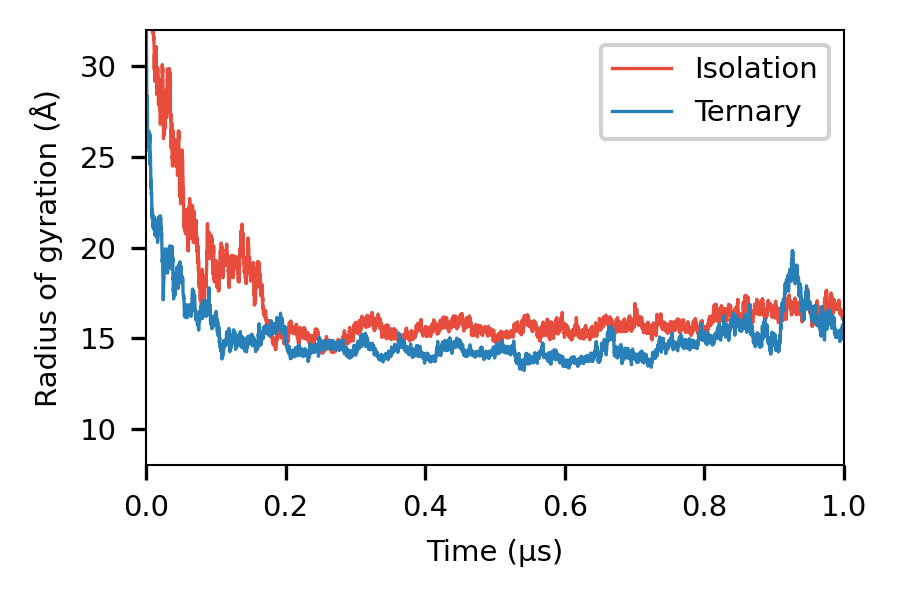

In [53]:
import numpy as np
import matplotlib.pyplot as plt


# 加载数据
rog1 = np.loadtxt('/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/6-MLL154/Analysis/RoG0.dat', comments="#")
rog2 = np.loadtxt('/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/6-MLL154-2/Analysis/RoG0.dat', comments="#")
rog3 = np.loadtxt('/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/6-MLL154-3/Analysis/RoG0.dat', comments="#")

rog4 = np.loadtxt('/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/7-MLL-alone/Analysis/RoG0.dat', comments="#")
rog5 = np.loadtxt('/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/7-MLL-alone2/analysis/RoG0.dat', comments="#")
rog6 = np.loadtxt('/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/7-MLL-alone4/Analysis/RoG0.dat', comments="#")

# 处理数据
time = rog1[:, 0] / 5000  # 转换为微秒

Ternary = (rog1[:, 1]+rog2[:, 1]+rog3[:, 1])/3
Monomer = (rog4[:, 1]+rog5[:, 1])/2

plt.figure(dpi=300, figsize=(3, 2))
# 绘制曲线
plt.plot(time, Monomer, color='#E74C3C', linewidth=0.8, label='Isolation')
plt.plot(time, Ternary, color='#2980B9', linewidth=0.8, label='Ternary')

# 设置坐标轴范围和刻度
plt.ylim([8, 32])
plt.xlim([0, 1])


# 设置坐标轴标签
plt.ylabel("Radius of gyration (Å)")
plt.xlabel("Time (µs)")

# 设置图例
plt.legend(loc='upper right', frameon=True, 
           framealpha=0.9, edgecolor='0.8', facecolor='white')


# 优化布局
plt.tight_layout()
plt.savefig('ROG.png', dpi=300, bbox_inches='tight', 
            transparent=True)
plt.show()

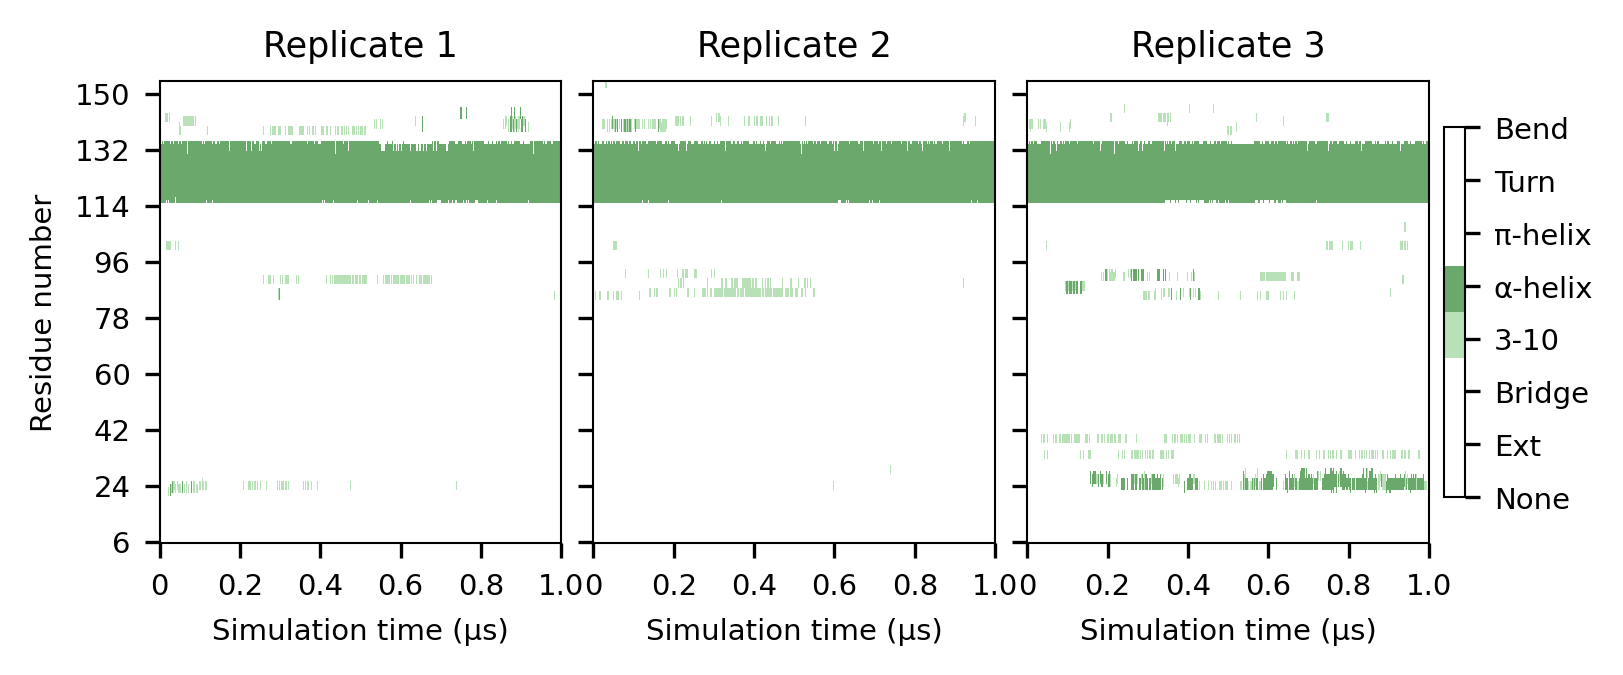

In [54]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


# ---------- 三个重复的数据文件路径 ----------
file_list = [
    "/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/6-MLL154/Analysis/3CD_3D-Ss.dat",
    "/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/6-MLL154-2/Analysis/3CD_3D-Ss.dat",
    "/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/6-MLL154-3/Analysis/3CD_3D-Ss.dat"
]
replicate_labels = ["Replicate 1", "Replicate 2", "Replicate 3"]

# ---------- 读取所有数据 ----------
data_list = []
for i, f in enumerate(file_list):
    data = np.loadtxt(f, comments="#")
    if data.shape[1] < 148:
        raise ValueError(f"{f} 的残基数不足 148")
    data_list.append(data[:, :148])

n_frames = data_list[0].shape[0]
n_residues = 148

# ---------- 颜色映射 ----------
colors = [
    '#FFFFFF',   # 0 - None
    '#FFFFFF',   # 1 - Ext
    '#FFFFFF',   # 2 - Bridge
    '#B8E1B8',   # 3 - 3-10 Helix
    '#6BA86B',   # 4 - Alpha Helix
    '#FFFFFF',   # 5 - Pi Helix
    '#FFFFFF',   # 6 - Turn
    '#FFFFFF'    # 7 - Bend
]
cmap = ListedColormap(colors)

# ---------- 建 1×3 子图 ----------
fig, axes = plt.subplots(
    1, 3,
    figsize=(6.5, 2), dpi=300,
    sharey=True,                # 三张图共享 Y 轴
    gridspec_kw={'wspace': 0.08}
)

# 坐标轴设置
xposition   = [0, 1000, 2000, 3000, 4000, 5000]
xlabels     = ['0', '0.2', '0.4', '0.6', '0.8', '1.0']
y_ticks     = np.arange(0, 154, 18)

im = None
for i, (ax, data) in enumerate(zip(axes, data_list)):
    # 转置：横轴=帧，纵轴=残基
    im = ax.imshow(
        data.T,
        aspect='auto',
        cmap=cmap,
        vmin=0, vmax=7,
        origin='lower',
        interpolation='nearest'
    )

    # X 轴
    ax.set_xticks(xposition)
    ax.set_xticklabels(xlabels)
    ax.set_xlabel("Simulation time (µs)")

    # Y 轴（只在最左侧显示刻度）
    ax.set_yticks(y_ticks)
    ax.set_ylim(-0.5, 148)

    if i == 0:
       ax.set_yticklabels([f"{v+6}" for v in y_ticks])
       ax.set_ylabel("Residue number")
    else:
       ax.tick_params(labelleft=False)   # ← 关键：只隐藏本子图刻度标签

    # 子图标题
    ax.set_title(replicate_labels[i])


cbar = fig.colorbar(
    im, ax=axes, ticks=[0,1,2,3,4,5,6,7],
    shrink=0.8, aspect=18, pad=0.01
)
cbar.ax.tick_params()
cbar_labels = ['None','Ext','Bridge','3-10','α-helix','π-helix','Turn','Bend']
cbar.ax.set_yticklabels(cbar_labels)


plt.savefig('secondary_structure_MLL_ternary_3replicates.png',
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

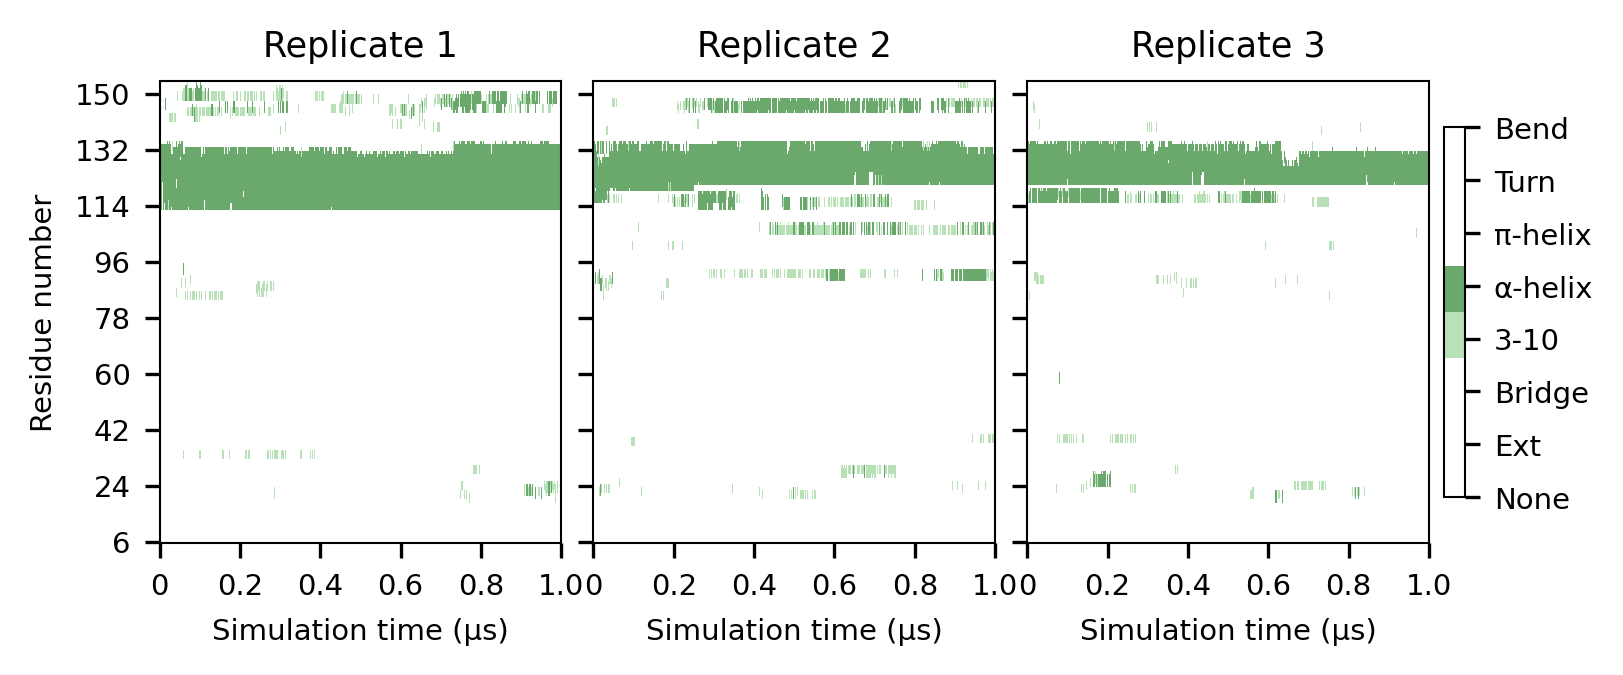

In [55]:
# ---------- 三个重复的数据文件路径 ----------
file_list = [
    "/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/7-MLL-alone/Analysis/3CD_3D-Ss.dat",
    "/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/7-MLL-alone2/analysis/3CD_3D-Ss.dat",
    "/home/jhsong/Menin_MLL_project/Menin-Mll/test-2-MML/7-MLL-alone4/Analysis/3CD_3D-Ss.dat"
]
replicate_labels = ["Replicate 1", "Replicate 2", "Replicate 3"]

# ---------- 读取数据 ----------
n_residues = 148
data_list = []
for i, f in enumerate(file_list):
    data = np.loadtxt(f, comments="#")
    if data.shape[1] < n_residues:
        raise ValueError(f"{f} 的残基数不足 {n_residues}")
    data_list.append(data[:, :n_residues])

# ---------- 颜色映射 ----------
colors = [
    '#FFFFFF',   # 0 - None
    '#FFFFFF',   # 1 - Ext
    '#FFFFFF',   # 2 - Bridge
    '#B8E1B8',   # 3 - 3-10 Helix
    '#6BA86B',   # 4 - Alpha Helix
    '#FFFFFF',   # 5 - Pi Helix
    '#FFFFFF',   # 6 - Turn
    '#FFFFFF'    # 7 - Bend
]
cmap = ListedColormap(colors)

# ---------- 1×3 子图 ----------
fig, axes = plt.subplots(
    1, 3,
    figsize=(6.5, 2), dpi=300,
    sharey=True,
    gridspec_kw={'wspace': 0.08}
)

# ---------- 坐标轴参数 ----------
xposition = [0, 1000, 2000, 3000, 4000, 5000]
xlabels   = ['0', '0.2', '0.4', '0.6', '0.8', '1.0']
y_ticks   = np.arange(0, 154, 18)

im = None
for i, (ax, data) in enumerate(zip(axes, data_list)):
    im = ax.imshow(
        data.T,                 
        aspect='auto',
        cmap=cmap,
        vmin=0, vmax=7,
        origin='lower',
        interpolation='nearest'
    )

    # X 轴
    ax.set_xticks(xposition)
    ax.set_xticklabels(xlabels,)
    ax.set_xlabel("Simulation time (µs)")

    # Y 轴
    ax.set_yticks(y_ticks)
    ax.set_ylim(-0.5, 148)

    if i == 0:
        # 残基编号 = y_tick + 6
        ax.set_yticklabels([f"{v+6}" for v in y_ticks])
        ax.set_ylabel("Residue number")
    else:
        ax.tick_params(labelleft=False)

    # 子图标题
    ax.set_title(replicate_labels[i])


cbar = fig.colorbar(
    im, ax=axes,
    ticks=[0, 1, 2, 3, 4, 5, 6, 7],
    shrink=0.8, aspect=18, pad=0.01
)
cbar_labels = ['None', 'Ext', 'Bridge', '3-10',
               'α-helix', 'π-helix', 'Turn', 'Bend']
cbar.ax.set_yticklabels(cbar_labels)

plt.savefig('secondary_structure_MLL-alone_3replicates.png',
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [60]:
##figs8

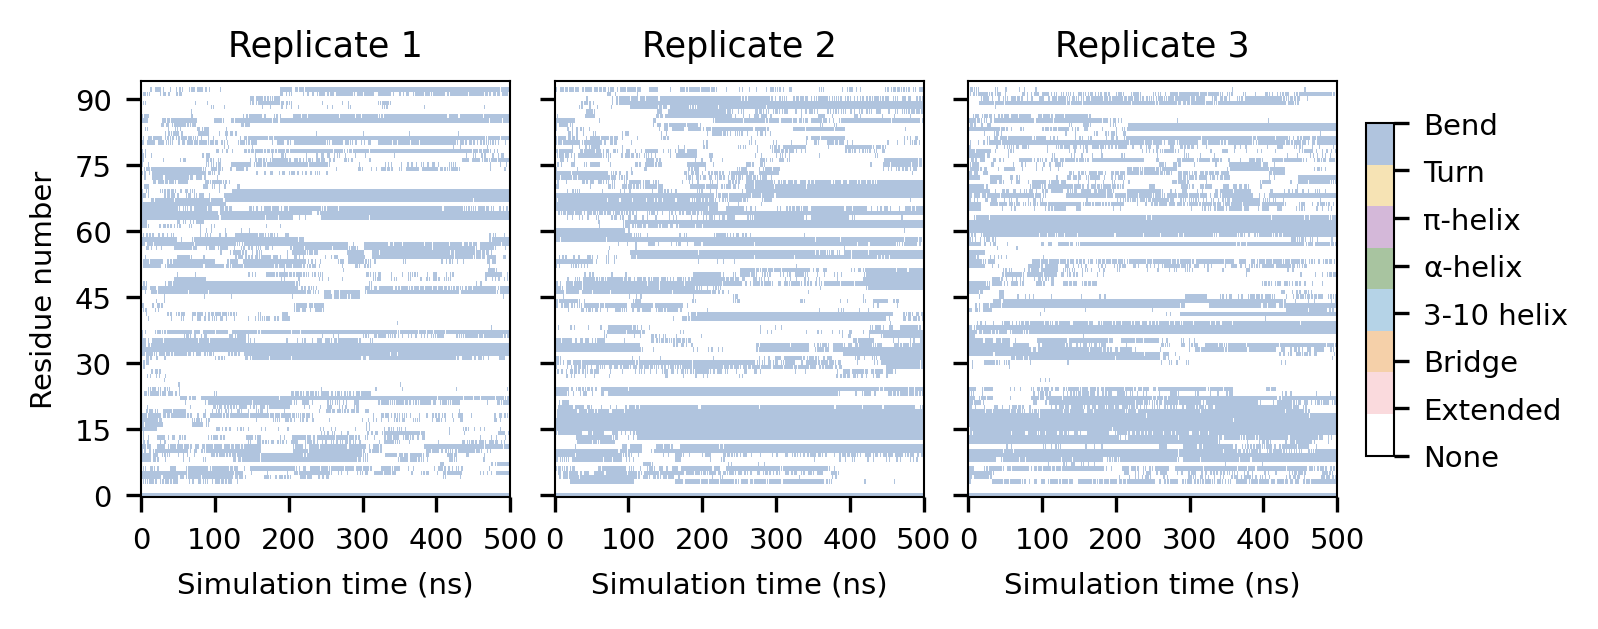

In [61]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# ---------- 三个重复的数据文件路径 ----------
file_list = [
    "/home/jhsong/CaN-project/amber/anlysis/complex/can-Ss.dat",
    "/home/jhsong/CaN-project/amber/anlysis/complex/can-Ss2.dat",
    "/home/jhsong/CaN-project/amber/anlysis/complex/can-Ss3.dat"
]
replicate_labels = ["Replicate 1", "Replicate 2", "Replicate 3"]

# ---------- 读取数据 ----------
n_residues = 94
data_list = []
for i, f in enumerate(file_list):
    data = np.loadtxt(f, comments="#")
    if data.shape[1] < n_residues:
        raise ValueError(f"{f} 的残基数不足 {n_residues}")
    data_list.append(data[:, :n_residues])

single_len = data_list[0].shape[0]  

colors = [
    '#FFFFFF',   # 0 - None
    '#FADADD',   # 1 - Extended
    '#F5D0A9',   # 2 - Bridge
    '#B5D3E7',   # 3 - 3-10 helix
    '#A8C4A0',   # 4 - Alpha helix
    '#D4B8D9',   # 5 - Pi helix
    '#F6E3B4',   # 6 - Turn
    '#B0C4DE'    # 7 - Bend
]
cmap = ListedColormap(colors)

# ---------- 1×3 子图 ----------
fig, axes = plt.subplots(
    1, 3,
    figsize=(6.2, 1.8), dpi=300,
    sharey=True,
    gridspec_kw={'wspace': 0.12}
)

# ---------- 坐标轴参数 ----------
step_interval = 400
xposition = list(range(0, single_len + 1, step_interval))
xlabels = [f"{i/step_interval*0.1:.1f}" for i in range(len(xposition))]  # 换算为 µs

y_ticks = np.arange(0, n_residues, 15)

im = None
for i, (ax, data) in enumerate(zip(axes, data_list)):
    im = ax.imshow(
        data.T,                  
        aspect='auto',
        cmap=cmap,
        vmin=0, vmax=7,
        origin='lower',
        interpolation='nearest'
    )

    # X 轴
    xposition  = [0, 400, 800, 1200, 1600, 2000]
    xlabels    = ['0', '100', '200', '300', '400', '500']
    ax.set_xticks(xposition)
    ax.set_xticklabels(xlabels)
    ax.set_xlabel("Simulation time (ns)")

    # Y 轴
    ax.set_yticks(y_ticks)
    ax.set_ylim(-0.5, n_residues)

    if i == 0:
        ax.set_yticklabels([f"{v}" for v in y_ticks])
        ax.set_ylabel("Residue number")
    else:
        ax.tick_params(labelleft=False)

    # 子图标题
    ax.set_title(replicate_labels[i], fontweight='normal')




cbar = fig.colorbar(
    im, ax=axes,
    ticks=[0, 1, 2, 3, 4, 5, 6, 7],
    shrink=0.8, aspect=12, pad=0.02
)
cbar_labels = ['None', 'Extended', 'Bridge', '3-10 helix',
               'α-helix', 'π-helix', 'Turn', 'Bend']
cbar.ax.set_yticklabels(cbar_labels)
cbar.ax.tick_params()

plt.savefig('ss-complex-3reps.png', dpi=300, bbox_inches='tight',
            transparent=True)
plt.show()

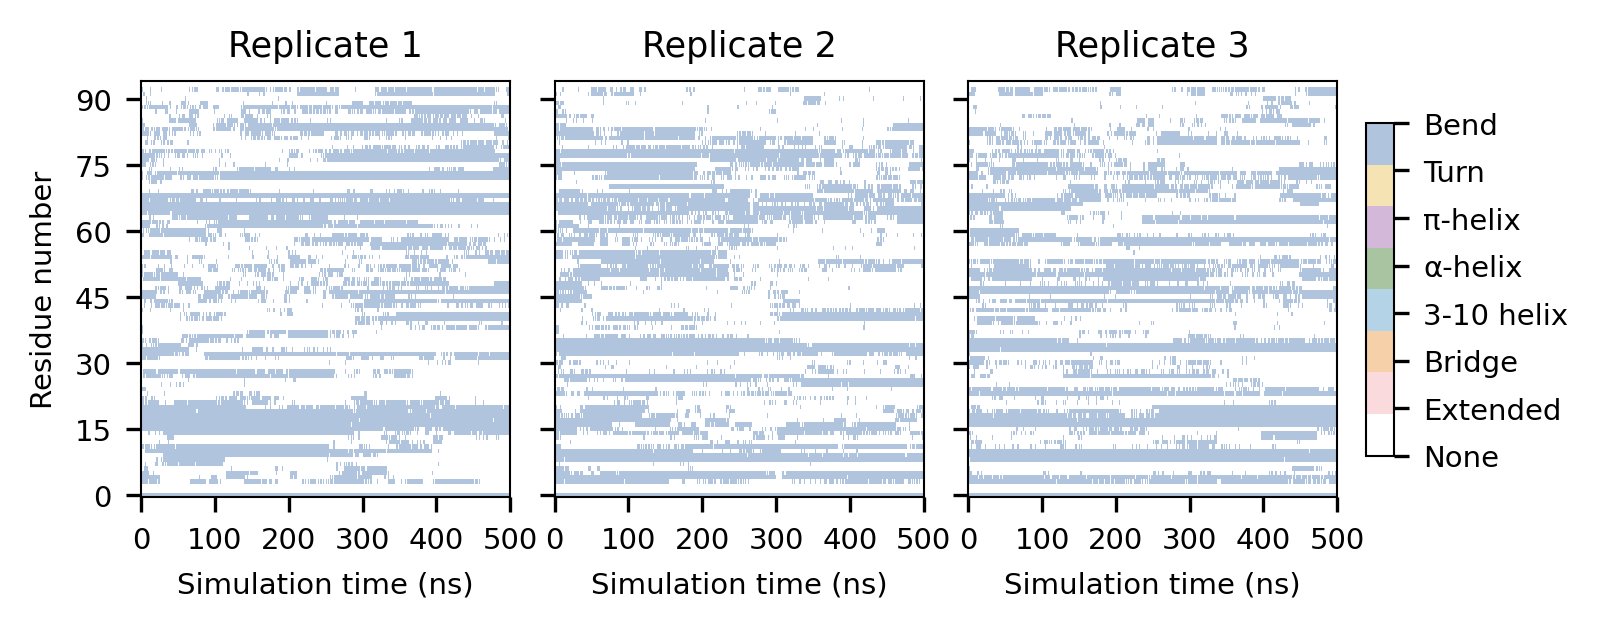

In [62]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# ---------- 三个重复的数据文件路径 ----------
file_list = [
    "/home/jhsong/CaN-project/amber/anlysis/monomer/can-Ss.dat",
    "/home/jhsong/CaN-project/amber/anlysis/monomer/can-Ss2.dat",
    "/home/jhsong/CaN-project/amber/anlysis/monomer/can-Ss3.dat"
]
replicate_labels = ["Replicate 1", "Replicate 2", "Replicate 3"]

# ---------- 读取数据 ----------
n_residues = 94
data_list = []
for i, f in enumerate(file_list):
    data = np.loadtxt(f, comments="#")
    if data.shape[1] < n_residues:
        raise ValueError(f"{f} 的残基数不足 {n_residues}")
    data_list.append(data[:, :n_residues])

single_len = data_list[0].shape[0]   

colors = [
    '#FFFFFF',   # 0 - None
    '#FADADD',   # 1 - Extended
    '#F5D0A9',   # 2 - Bridge
    '#B5D3E7',   # 3 - 3-10 helix
    '#A8C4A0',   # 4 - Alpha helix
    '#D4B8D9',   # 5 - Pi helix
    '#F6E3B4',   # 6 - Turn
    '#B0C4DE'    # 7 - Bend
]
cmap = ListedColormap(colors)

# ---------- 1×3 子图 ----------
fig, axes = plt.subplots(
    1, 3,
    figsize=(6.2, 1.8), dpi=300,
    sharey=True,
    gridspec_kw={'wspace': 0.12}
)

# ---------- 坐标轴参数 ----------
step_interval = 400
xposition = list(range(0, single_len + 1, step_interval))
xlabels = [f"{i/step_interval*0.1:.1f}" for i in range(len(xposition))]  # 换算为 µs

y_ticks = np.arange(0, n_residues, 15)

im = None
for i, (ax, data) in enumerate(zip(axes, data_list)):
    im = ax.imshow(
        data.T,                  
        aspect='auto',
        cmap=cmap,
        vmin=0, vmax=7,
        origin='lower',
        interpolation='nearest'
    )

    # X 轴
    xposition  = [0, 400, 800, 1200, 1600, 2000]
    xlabels    = ['0', '100', '200', '300', '400', '500']
    ax.set_xticks(xposition)
    ax.set_xticklabels(xlabels)
    ax.set_xlabel("Simulation time (ns)")

    # Y 轴
    ax.set_yticks(y_ticks)
    ax.set_ylim(-0.5, n_residues)

    if i == 0:
        ax.set_yticklabels([f"{v}" for v in y_ticks])
        ax.set_ylabel("Residue number")
    else:
        ax.tick_params(labelleft=False)

    # 子图标题
    ax.set_title(replicate_labels[i], fontweight='normal')




cbar = fig.colorbar(
    im, ax=axes,
    ticks=[0, 1, 2, 3, 4, 5, 6, 7],
    shrink=0.8, aspect=12, pad=0.02
)
cbar_labels = ['None', 'Extended', 'Bridge', '3-10 helix',
               'α-helix', 'π-helix', 'Turn', 'Bend']
cbar.ax.set_yticklabels(cbar_labels)
cbar.ax.tick_params()

plt.savefig('ss-complex-3reps-mon.png', dpi=300, bbox_inches='tight',
            transparent=True)
plt.show()

In [56]:
#figs10

绘制帧数: 1000


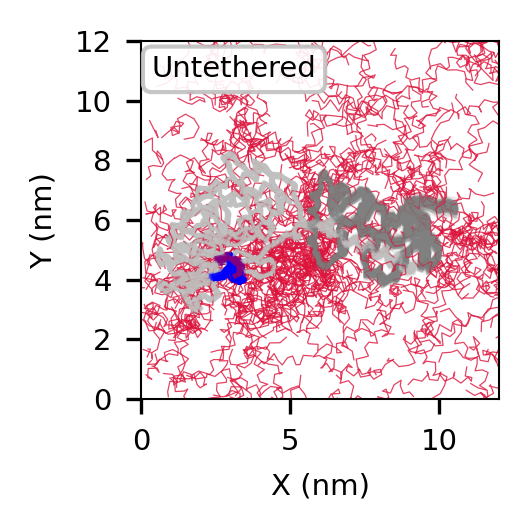

In [57]:
import mdtraj as md
import matplotlib.pyplot as plt
import numpy as np



# ====== 加载轨迹和拓扑 ======
t = md.load('/home/jhsong/CaN-project/total/5-AID1/step5_production_1-3.xtc',
            top='/home/jhsong/CaN-project/total/5-AID1/step3_charmm2gmx.pdb')
top = t.topology

# ====== 原子选择 ======
selection = top.select('resid 0 to 544 and name BB')
lig = top.select('resid 360 to 378 and name BB')

# ====== 结构对齐 ======
alignment_indices = top.select('resid 1 to 359 and name BB')
t_aligned = t.superpose(t[0], atom_indices=alignment_indices)

# ====== 提取坐标 ======
xcord = t_aligned.xyz[:, selection, 0]
ycord = t_aligned.xyz[:, selection, 1]
lig_x = t_aligned.xyz[:, lig, 0]
lig_y = t_aligned.xyz[:, lig, 1]

# ====== 分段函数 ======
def find_segments(x_coords, y_coords, max_gap=2.0):
    segments = []
    if len(x_coords) == 0:
        return segments
    current = [0]
    for i in range(1, len(x_coords)):
        dist = np.hypot(x_coords[i] - x_coords[i-1], y_coords[i] - y_coords[i-1])
        if dist <= max_gap:
            current.append(i)
        else:
            if len(current) > 1:
                segments.append(current)
            current = [i]
    if len(current) > 1:
        segments.append(current)
    return segments

# ====== 绘图 ======
fig, ax = plt.subplots(figsize=(1.78, 1.78), dpi=300)  

frames_to_plot = min(1000, t_aligned.n_frames)
print(f"绘制帧数: {frames_to_plot}")

# ---------- 配色 ----------
color_N = 'silver'          # N端灰
color_C = 'gray'          # C端灰
color_lig = 'crimson'       # 配体橙红
alpha_lig = 0.8
lw_lig = 0.3                 # 加粗

color_interface1 = 'purple'
color_interface2 = 'blue'
alpha_interface = 1
lw_interface = 1.2           # 加粗突出

# ---------- 绘制轨迹 ----------
for i in range(0, frames_to_plot, 3):
    # 背景蛋白（适当加粗，去掉rasterized）
    ax.plot(xcord[i, 1:359], ycord[i, 1:359],
            color=color_N, alpha=0.1, lw=0.4)
    ax.plot(xcord[i, 380:544], ycord[i, 380:544],
            color=color_C, alpha=0.1, lw=0.4)
    
    # 配体
    segs = find_segments(lig_x[i], lig_y[i])
    for seg in segs:
        ax.plot(lig_x[i, seg], lig_y[i, seg],
                color=color_lig, alpha=alpha_lig, lw=lw_lig)
    
    # 结合界面
    ax.plot(xcord[i, 267:276], ycord[i, 267:276],
            color=color_interface2, alpha=alpha_interface, lw=lw_interface)
    ax.plot(xcord[i, 238:244], ycord[i, 238:244],
            color=color_interface1, alpha=alpha_interface, lw=lw_interface)
  
# ====== 坐标轴设置 ======
ax.set_xlim(0, 12)
ax.set_ylim(0, 12)
#ax.set_xticks(np.arange(0, 13, 2))
#ax.set_yticks(np.arange(0, 13, 2))
ax.set_xlabel('X (nm)')
ax.set_ylabel('Y (nm)')

# 添加S1标签 
ax.annotate('Untethered', 
            xy=(0.03, 0.96), 
            xycoords='axes fraction',
            color='black',
            bbox=dict(boxstyle="round,pad=0.3", 
                     facecolor='white', 
                     alpha=0.9, 
                     edgecolor='silver', 
                     linewidth=1),
            ha='left', 
            va='top',
            zorder=10)

ax.set_aspect('equal')
ax.grid(False)



plt.tight_layout()

plt.savefig('trajectory_noIDR.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

构象分布在粉色区域内的概率比例: 0.0163 (1.63%)
粉色区域绝对概率质量: 0.015975
整个构象空间总概率质量: 0.978541
归一化验证: 0.016326


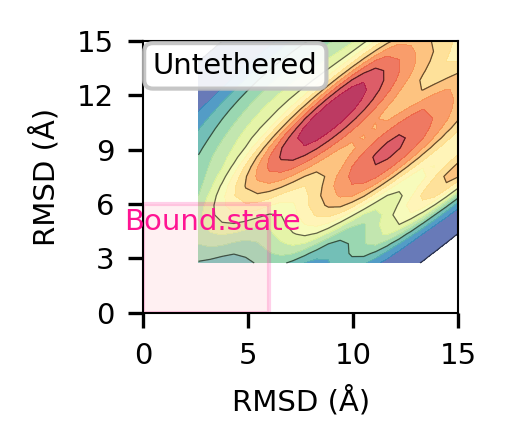

In [59]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
import matplotlib


import matplotlib.patches as patches
from matplotlib.patches import Rectangle
rmsd1 = np.loadtxt('/home/jhsong/CaN-project/total/5-AID1/rmsd-IDR2.dat', comments="#")
rmsd2 = np.loadtxt('/home/jhsong/CaN-project/total/5-AID1/rmsd-IDR3.dat', comments="#")


x = np.array(rmsd1[:, 1])
y = np.array(rmsd2[:, 1])
min_length = min(len(x), len(y))
x = x[:min_length]
y = y[:min_length]

xy = np.vstack([x, y])
z = gaussian_kde(xy)(xy)

# 对密度值进行归一化
z_normalized = (z - z.min()) / (z.max() - z.min())

cmap = 'Spectral_r'

# 创建画布

fig, ax = plt.subplots(figsize=(1.7,1.5 ), dpi=300)

xi = np.linspace(x.min(), x.max(), 150)
yi = np.linspace(y.min(), y.max(), 150)
xi, yi = np.meshgrid(xi, yi)

xy_grid = np.vstack([xi.flatten(), yi.flatten()])
zi = gaussian_kde(xy)(xy_grid)
zi = zi.reshape(xi.shape)
zi_normalized = (zi - zi.min()) / (zi.max() - zi.min())

# 设置等高线密度范围
density_min = 0.001
density_max = zi_normalized.max()
contour_levels = np.linspace(density_min, density_max, 15)

# 绘制等高线填充
contourf = ax.contourf(xi, yi, zi_normalized, 
                       levels=contour_levels, 
                       cmap=cmap, 
                       alpha=0.85,
                       vmin=density_min,
                       vmax=density_max,
                       extend='max')

# 绘制等高线
contour_lines = ax.contour(xi, yi, zi_normalized, 
                          levels=contour_levels[::3],
                          colors='black', 
                          linewidths=0.3, 
                          alpha=0.6,
                          linestyles='-')



# 设置坐标轴范围
ax.set_xlim([0, 15])
ax.set_ylim([0, 15])


ax.set_yticks([0, 3, 6, 9,12, 15])
ax.set_yticklabels(['0', '3', '6', '9', '12','15'])  

ax.set_xlabel('RMSD (Å)')
ax.set_ylabel('RMSD (Å)')


ax.annotate('Untethered', 
            xy=(0.03, 0.96), 
            xycoords='axes fraction',
            color='black',
            bbox=dict(boxstyle="round,pad=0.3", 
                     facecolor='white', 
                     alpha=0.9, 
                     edgecolor='silver', 
                     linewidth=1),
            ha='left', 
            va='top',
            zorder=10)


# 添加长方形区域
rect = Rectangle((0, 0), 6, 6, 
                 linewidth=1, 
                 edgecolor='#FF1493', # 深粉色边框
                 facecolor='#FFB6C1',# 浅粉色填充 
                 alpha=0.2, 
                 label='Bound.state')
ax.add_patch(rect)

# 简洁的无框标签
ax.text(3.3, 5, 'Bound.state', 
        fontsize=7, 
        color='#FF1493',
        ha='center',
        va='center',
        zorder=10)

# 优化布局
plt.savefig('noIDR.png', dpi=300, bbox_inches='tight', 
            transparent=True)
plt.tight_layout()


# 定义粉色区域范围 
pink_region_x_range = [0, 6]  # X轴范围
pink_region_y_range = [0, 6]    # Y轴范围

# 更精确的体积计算方法
def calculate_region_volume_ratio(x_data, y_data, x_range, y_range, grid_resolution=100):
    """计算指定区域在整个构象空间的体积比例"""
    # 创建整个数据空间的网格
    x_grid = np.linspace(x_data.min(), x_data.max(), grid_resolution)
    y_grid = np.linspace(y_data.min(), y_data.max(), grid_resolution)
    X, Y = np.meshgrid(x_grid, y_grid)
    
    # 计算整个空间的密度
    xy_all = np.vstack([x_data, y_data])
    kde_all = gaussian_kde(xy_all)
    positions = np.vstack([X.ravel(), Y.ravel()])
    Z = kde_all(positions).reshape(X.shape)
    
    # 提取目标区域
    region_mask = (X >= x_range[0]) & (X <= x_range[1]) & \
                  (Y >= y_range[0]) & (Y <= y_range[1])
    
    # 计算体积
    dx = x_grid[1] - x_grid[0]
    dy = y_grid[1] - y_grid[0]
    
    # 计算粉色区域体积和总体积
    region_volume = np.sum(Z[region_mask]) * dx * dy
    total_volume = np.sum(Z) * dx * dy
    
    # 计算比例
    volume_ratio = region_volume / total_volume
    
    return volume_ratio, region_volume, total_volume, Z, X, Y, region_mask
# 使用修正的函数计算
volume_ratio, region_vol, total_vol, Z_full, X_full, Y_full, mask = calculate_region_volume_ratio(
    x, y, pink_region_x_range, pink_region_y_range)


print(f"构象分布在粉色区域内的概率比例: {volume_ratio:.4f} ({volume_ratio*100:.2f}%)")
print(f"粉色区域绝对概率质量: {region_vol:.6f}")
print(f"整个构象空间总概率质量: {total_vol:.6f}")
print(f"归一化验证: {region_vol/total_vol:.6f}")